In [ ]:
# =============================================================================
# CELLULE 1 : Installation et imports
# =============================================================================
# Temps estimé : ~30 secondes
#
# On installe les dépendances nécessaires pour cette partie.
# 'unidecode' sert à comparer des textes sans accents (ex: "é" → "e")
# C'est utile pour retrouver "Marseille" dans "marsseille".
# =============================================================================

!pip install unidecode --quiet

import re
import json
import os
import unicodedata
from collections import Counter, defaultdict

# unidecode transforme "éàû" → "eau", utile pour le matching sans accents
from unidecode import unidecode

print("✅ Imports OK")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.8/235.8 kB 4.9 MB/s eta 0:00:00
✅ Imports OK


In [ ]:
# =============================================================================
# CELLULE 2 : Upload des fichiers dans Colab
# =============================================================================
# Temps estimé : ~10 secondes
#
# Tu dois uploader tes 2 fichiers dans Colab :
#   - full_input.txt  (format: sentenceID,phrase)
#   - full_output.txt (format: sentenceID,origin,destination)
#
# Option A : Upload manuel via le panneau fichiers de Colab
# Option B : Upload depuis Google Drive (décommente le code ci-dessous)
# =============================================================================

# --- Option A : Upload manuel ---
# Utilise le panneau de fichiers à gauche dans Colab (icône dossier)
# Glisse tes fichiers full_input.txt et full_output.txt dedans

# --- Option B : Google Drive ---
# from google.colab import drive
# drive.mount('/content/drive')
# !cp /content/drive/MyDrive/TON_DOSSIER/full_input.txt .
# !cp /content/drive/MyDrive/TON_DOSSIER/full_output.txt .

# --- Vérifie que les fichiers sont là ---
for f in ['full_input.txt', 'full_output.txt']:
    if os.path.exists(f):
        with open(f, 'r', encoding='utf-8') as fh:
            lines = fh.readlines()
        print(f"✅ {f} : {len(lines)} lignes")
    else:
        print(f"❌ {f} : FICHIER MANQUANT ! Upload-le dans Colab.")



✅ full_input.txt : 19996 lignes
✅ full_output.txt : 19996 lignes


In [ ]:
# =============================================================================
# CELLULE 3 : Chargement et validation des données brutes
# =============================================================================
# Temps estimé : ~2 secondes
#
# On charge les deux fichiers et on les associe par sentenceID.
#
# FORMAT ATTENDU :
#   full_input.txt  → "1,Mon ami Albert veut aller de Tours à Bordeaux"
#   full_output.txt → "1,Tours,Bordeaux"  ou  "201,INVALID,"
#
# POURQUOI VALIDER ?
#   Si un ID est dans l'input mais pas dans l'output (ou inversement),
#   ça va créer des problèmes plus tard. On vérifie tout maintenant.
# =============================================================================

def load_raw_data(input_path, output_path):
    """
    Charge les fichiers input et output et les associe par sentenceID.

    Retourne une liste de dicts :
    [
        {
            'id': 1,
            'sentence': "Mon ami Albert veut aller de Tours à Bordeaux",
            'origin': "Tours",
            'destination': "Bordeaux",
            'is_valid': True
        },
        ...
    ]
    """
    # --- Charger les inputs ---
    inputs = {}
    with open(input_path, 'r', encoding='utf-8') as f:
        for line_num, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            # Séparer l'ID de la phrase (premier virgule uniquement)
            idx = line.find(',')
            if idx == -1:
                print(f"  ⚠️ Input ligne {line_num}: pas de virgule → '{line[:50]}'")
                continue
            try:
                sid = int(line[:idx].strip())
            except ValueError:
                print(f"  ⚠️ Input ligne {line_num}: ID non numérique → '{line[:50]}'")
                continue
            sentence = line[idx+1:].strip().strip('"')
            inputs[sid] = sentence

    # --- Charger les outputs ---
    outputs = {}
    with open(output_path, 'r', encoding='utf-8') as f:
        for line_num, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            parts = line.split(',')
            if len(parts) < 2:
                print(f"  ⚠️ Output ligne {line_num}: format invalide → '{line[:50]}'")
                continue
            try:
                sid = int(parts[0].strip())
            except ValueError:
                print(f"  ⚠️ Output ligne {line_num}: ID non numérique → '{line[:50]}'")
                continue
            origin = parts[1].strip() if len(parts) > 1 else ""
            dest = parts[2].strip() if len(parts) > 2 else ""
            outputs[sid] = (origin, dest)

    # --- Associer input ↔ output ---
    data = []
    matched = 0
    input_only = 0
    output_only = 0

    all_ids = sorted(set(inputs.keys()) | set(outputs.keys()))
    for sid in all_ids:
        if sid in inputs and sid in outputs:
            origin, dest = outputs[sid]
            is_valid = origin.upper() != "INVALID" and origin != ""
            data.append({
                'id': sid,
                'sentence': inputs[sid],
                'origin': origin if is_valid else "",
                'destination': dest if is_valid else "",
                'is_valid': is_valid
            })
            matched += 1
        elif sid in inputs:
            input_only += 1
        else:
            output_only += 1

    # --- Rapport ---
    n_valid = sum(1 for d in data if d['is_valid'])
    n_invalid = sum(1 for d in data if not d['is_valid'])

    print(f"\n{'='*60}")
    print(f" CHARGEMENT DES DONNÉES")
    print(f"{'='*60}")
    print(f" Lignes input        : {len(inputs)}")
    print(f" Lignes output       : {len(outputs)}")
    print(f" Matchées (ID↔ID)    : {matched}")
    if input_only > 0:
        print(f" ⚠️ Input sans output : {input_only}")
    if output_only > 0:
        print(f" ⚠️ Output sans input : {output_only}")
    print(f" Phrases valides     : {n_valid} ({n_valid/len(data)*100:.1f}%)")
    print(f" Phrases invalides   : {n_invalid} ({n_invalid/len(data)*100:.1f}%)")
    print(f"{'='*60}")

    return data


# --- Exécution ---
data = load_raw_data('full_input.txt', 'full_output.txt')

# Aperçu
print("\n--- Exemples valides ---")
for d in data[:3]:
    if d['is_valid']:
        print(f"  [{d['id']}] {d['sentence'][:70]}  →  {d['origin']} → {d['destination']}")

print("\n--- Exemples invalides ---")
for d in data:
    if not d['is_valid']:
        print(f"  [{d['id']}] {d['sentence'][:70]}  →  INVALID")
        break




 CHARGEMENT DES DONNÉES
 Lignes input        : 19996
 Lignes output       : 19996
 Matchées (ID↔ID)    : 19996
 Phrases valides     : 16088 (80.5%)
 Phrases invalides   : 3908 (19.5%)

--- Exemples valides ---
  [1] Mon ami Albert veut aller de Tours à Bordeaux  →  Tours → Bordeaux
  [2] Je vais voir Albert à Nice en partant de Marseille  →  Marseille → Nice
  [3] Albert m'a dit de prendre le train de Paris à Lyon  →  Paris → Lyon

--- Exemples invalides ---
  [201] Quel temps fait-il à Lyon ?  →  INVALID


In [ ]:
# =============================================================================
# CELLULE 4 : Pré-tokenisation par mots
# =============================================================================
# Temps estimé : ~1 seconde
#
# POURQUOI PRÉ-TOKENISER ?
#   CamemBERT va faire sa propre tokenisation (sub-word), mais AVANT ça,
#   on doit découper la phrase en mots pour savoir quel label BIO donner
#   à chaque mot. Ensuite (Partie 2), on alignera les labels des mots
#   avec les sub-tokens de CamemBERT.
#
# STRATÉGIE DE TOKENISATION :
#   C'est un choix important. On doit décider comment gérer :
#   - "Saint-Malo"       → ["Saint-Malo"] (1 token) ou ["Saint", "-", "Malo"] (3 tokens) ?
#   - "Aix-en-Provence"  → ["Aix-en-Provence"] (1 token) ou 4 tokens ?
#   - "l'ami"            → ["l'ami"] ou ["l'", "ami"] ?
#
#   NOTRE CHOIX : On sépare sur les espaces et la ponctuation,
#   MAIS on garde les tirets collés aux mots (pour les villes composées).
#   "De Saint-Malo à Rennes" → ["De", "Saint-Malo", "à", "Rennes"]
#   "J'ai besoin"            → ["J'", "ai", "besoin"]
#
#   Pourquoi ? Parce que si "Saint-Malo" est 1 token, il suffit d'un seul
#   label B-DEST. Si on le sépare en 3 tokens, il faut B-DEST I-DEST I-DEST
#   et le matching devient plus compliqué.
# =============================================================================

def tokenize_words(text):
    """
    Pré-tokenise une phrase en mots.

    Règles :
    - Sépare sur les espaces
    - Sépare la ponctuation (. , ! ? ; :) en tokens individuels
    - GARDE les tirets à l'intérieur des mots (Saint-Malo reste un token)
    - Sépare les apostrophes : "l'ami" → ["l'", "ami"]
    - Filtre les tokens vides

    Exemples :
        "De Saint-Malo à Rennes !"  → ["De", "Saint-Malo", "à", "Rennes", "!"]
        "J'ai besoin d'un billet"   → ["J'", "ai", "besoin", "d'", "un", "billet"]
        "marsseille lyon"           → ["marsseille", "lyon"]
    """
    # Étape 1 : Séparer les apostrophes → "l'ami" devient "l' ami"
    text = re.sub(r"(\w)'(\w)", r"\1' \2", text)

    # Étape 2 : Séparer la ponctuation (sauf les tirets à l'intérieur des mots)
    # On met un espace avant/après . , ! ? ; : ( ) « » " "
    text = re.sub(r'([.!?,;:()«»""…\[\]])', r' \1 ', text)

    # Étape 3 : Séparer sur les espaces et filtrer les vides
    tokens = [t for t in text.split() if t.strip()]

    return tokens


# --- Tests ---
test_cases = [
    "De Saint-Malo à Rennes !",
    "J'ai besoin d'un billet de Aix-en-Provence à Marseille",
    "marsseille lyon",
    "je ve aler a pari depui tulouse",
    "Avec mes amis florence et paris je voudrais aller de paris à florence",
    "slt tu peux me trouver un train paris lyon",
    "De Chalon-sur-Saône à Dijon",
    "Billet de Clermont-Ferrand à Saint-Étienne",
]

print("=== TESTS DE TOKENISATION ===\n")
for text in test_cases:
    tokens = tokenize_words(text)
    print(f"  '{text}'")
    print(f"  → {tokens}\n")


# =============================================================================


=== TESTS DE TOKENISATION ===

  'De Saint-Malo à Rennes !'
  → ['De', 'Saint-Malo', 'à', 'Rennes', '!']

  'J'ai besoin d'un billet de Aix-en-Provence à Marseille'
  → ["J'", 'ai', 'besoin', "d'", 'un', 'billet', 'de', 'Aix-en-Provence', 'à', 'Marseille']

  'marsseille lyon'
  → ['marsseille', 'lyon']

  'je ve aler a pari depui tulouse'
  → ['je', 've', 'aler', 'a', 'pari', 'depui', 'tulouse']

  'Avec mes amis florence et paris je voudrais aller de paris à florence'
  → ['Avec', 'mes', 'amis', 'florence', 'et', 'paris', 'je', 'voudrais', 'aller', 'de', 'paris', 'à', 'florence']

  'slt tu peux me trouver un train paris lyon'
  → ['slt', 'tu', 'peux', 'me', 'trouver', 'un', 'train', 'paris', 'lyon']

  'De Chalon-sur-Saône à Dijon'
  → ['De', 'Chalon-sur-Saône', 'à', 'Dijon']

  'Billet de Clermont-Ferrand à Saint-Étienne'
  → ['Billet', 'de', 'Clermont-Ferrand', 'à', 'Saint-Étienne']



In [ ]:
# =============================================================================
# CELLULE 5 : Matching des entités dans les tokens
# =============================================================================
# Temps estimé : ~1 seconde
#
# C'EST LE CŒUR DE LA PARTIE 1.
#
# PROBLÈME :
#   On a la phrase tokenisée : ["marsseille", "lyon"]
#   Et l'output nous dit : origin=Marseille, destination=Lyon
#   Comment retrouver "Marseille" dans "marsseille" ?
#
# STRATÉGIE EN 3 NIVEAUX :
#   Niveau 1 : Match EXACT (case-insensitive)
#     "Paris" dans ["de", "Paris", "à"] → trouvé directement
#
#   Niveau 2 : Match SANS ACCENTS
#     "Saint-Étienne" dans ["saint-etienne"] → trouvé après normalisation
#
#   Niveau 3 : Match FUZZY (pour les fautes d'orthographe)
#     "Marseille" dans ["marsseille"] → trouvé par similarité
#
# POURQUOI PAS JUSTE DU FUZZY PARTOUT ?
#   Parce que le fuzzy matching peut créer des faux positifs.
#   "Nice" pourrait matcher avec "nice" (l'adjectif) même quand c'est pas
#   une ville. On utilise le fuzzy seulement quand les niveaux 1-2 échouent.
# =============================================================================

def normalize_for_matching(text):
    """
    Normalise un texte pour faciliter la comparaison.
    Supprime accents, met en minuscules.

    "Saint-Étienne" → "saint-etienne"
    "Aix-en-Provence" → "aix-en-provence"
    """
    # Décomposer les caractères accentués puis supprimer les accents
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    return text.lower()


def fuzzy_similarity(s1, s2):
    """
    Calcule la similarité entre deux chaînes (0.0 à 1.0).
    Utilise la distance de Levenshtein normalisée.

    "marseille" vs "marsseille" → ~0.9 (très similaire)
    "paris" vs "brest" → ~0.2 (très différent)
    """
    # Implémentation simple de la distance de Levenshtein
    if not s1 or not s2:
        return 0.0
    len1, len2 = len(s1), len(s2)
    # Matrice de distances
    matrix = [[0] * (len2 + 1) for _ in range(len1 + 1)]
    for i in range(len1 + 1):
        matrix[i][0] = i
    for j in range(len2 + 1):
        matrix[0][j] = j
    for i in range(1, len1 + 1):
        for j in range(1, len2 + 1):
            cost = 0 if s1[i-1] == s2[j-1] else 1
            matrix[i][j] = min(
                matrix[i-1][j] + 1,      # suppression
                matrix[i][j-1] + 1,      # insertion
                matrix[i-1][j-1] + cost  # substitution
            )
    distance = matrix[len1][len2]
    max_len = max(len1, len2)
    return 1.0 - (distance / max_len) if max_len > 0 else 1.0


def expand_abbreviations(text):
    """
    Remplace les abréviations courantes dans les noms de villes.
    "st" → "saint", "ste" → "sainte", etc.
    Travaille sur du texte normalisé (minuscules).
    """
    abbreviations = {
        'st': 'saint', 'ste': 'sainte',
        'mt': 'mont', 'pt': 'pont',
    }
    words = text.split('-')
    expanded = []
    for w in words:
        w_parts = w.split()
        expanded_parts = [abbreviations.get(p, p) for p in w_parts]
        expanded.append(' '.join(expanded_parts))
    return '-'.join(expanded)


def find_entity_in_tokens(tokens, entity, threshold=0.70):
    """
    Retrouve une entité (origin ou destination) dans les tokens de la phrase.

    Essaie 5 niveaux de matching :
      1. Exact (case-insensitive)
      2. Sans accents
      3. Avec expansion des abréviations (st→saint)
      4. En éclatant les tirets (chercher "saint malo" pour "Saint-Malo")
      5. Match partiel (chercher "Lyon" dans "Lyon-Part-Dieu")
      6. Fuzzy (pour les fautes d'orthographe)

    Paramètres :
        tokens    : liste de mots de la phrase ["de", "marsseille", "à", "lyon"]
        entity    : nom de l'entité à trouver "Marseille"
        threshold : seuil minimum de similarité pour le fuzzy (0.70 = 70%)

    Retourne :
        (start, end) : indices des tokens matchés, ou None si non trouvé
    """
    if not entity or not tokens:
        return None

    # Tokeniser l'entité de la même manière que la phrase
    entity_tokens = tokenize_words(entity)
    entity_len = len(entity_tokens)

    # Préparer les versions normalisées
    tokens_lower = [t.lower() for t in tokens]
    tokens_norm = [normalize_for_matching(t) for t in tokens]
    entity_lower = [t.lower() for t in entity_tokens]
    entity_norm = [normalize_for_matching(t) for t in entity_tokens]

    best_match = None
    best_score = 0.0

    # =========================================================
    # NIVEAU 1-3 : Match exact, sans accents, avec abréviations
    # =========================================================
    for i in range(len(tokens) - entity_len + 1):
        window_lower = tokens_lower[i:i + entity_len]
        window_norm = tokens_norm[i:i + entity_len]

        # NIVEAU 1 : Match exact (case-insensitive)
        if window_lower == entity_lower:
            return (i, i + entity_len)

        # NIVEAU 2 : Match sans accents
        if window_norm == entity_norm:
            return (i, i + entity_len)

        # NIVEAU 3 : Avec expansion d'abréviations
        window_expanded = [expand_abbreviations(w) for w in window_norm]
        entity_expanded = [expand_abbreviations(w) for w in entity_norm]
        if window_expanded == entity_expanded:
            return (i, i + entity_len)

    # =========================================================
    # NIVEAU 4 : Entité avec tiret, cherchée sans tiret
    # Ex: entity="Saint-Malo" → chercher ["saint", "malo"] dans les tokens
    # =========================================================
    if '-' in entity:
        # Éclater l'entité sur les tirets
        entity_split = entity.replace('-', ' ').split()
        entity_split_norm = [normalize_for_matching(t) for t in entity_split]
        split_len = len(entity_split_norm)

        for i in range(len(tokens) - split_len + 1):
            window = tokens_norm[i:i + split_len]
            # Match direct
            if window == entity_split_norm:
                return (i, i + split_len)
            # Match avec abréviations (st→saint)
            window_exp = [expand_abbreviations(w) for w in window]
            entity_exp = [expand_abbreviations(w) for w in entity_split_norm]
            if window_exp == entity_exp:
                return (i, i + split_len)
            # Match fuzzy sur les composants
            if split_len >= 2:
                sims = [fuzzy_similarity(window[j], entity_split_norm[j])
                        for j in range(split_len)]
                avg_sim = sum(sims) / len(sims)
                if avg_sim > best_score and avg_sim >= threshold:
                    best_score = avg_sim
                    best_match = (i, i + split_len)

    # =========================================================
    # NIVEAU 5 : Match partiel (entité contenue dans un token)
    # Ex: entity="Lyon", token="Lyon-Part-Dieu" → match !
    # Utile pour les noms de gares
    # =========================================================
    if entity_len == 1:
        entity_single = entity_norm[0]
        for i, tok_norm in enumerate(tokens_norm):
            # Le token commence par l'entité (suivi d'un tiret)
            if tok_norm.startswith(entity_single + '-') or tok_norm == entity_single:
                if tok_norm != entity_single:  # Déjà testé au niveau 1-2
                    return (i, i + 1)
            # Ou le token contient l'entité après un tiret
            # Ex: "Paris-Gare-de-Lyon" contient "Paris"
            if '-' in tok_norm:
                parts = tok_norm.split('-')
                if entity_single in parts:
                    return (i, i + 1)

    # =========================================================
    # NIVEAU 6 : Match fuzzy (pour les fautes d'orthographe)
    # Seuil adaptatif : plus strict pour les mots courts
    # =========================================================
    for i in range(len(tokens) - entity_len + 1):
        window_norm = tokens_norm[i:i + entity_len]

        if entity_len == 1:
            sim = fuzzy_similarity(window_norm[0], entity_norm[0])
            # Seuil adaptatif : les mots courts ont besoin d'un seuil plus bas
            # car 1 lettre de différence sur 4 = 25% d'erreur
            word_len = max(len(window_norm[0]), len(entity_norm[0]))
            adaptive_threshold = threshold if word_len >= 6 else max(0.55, threshold - 0.15)
            if sim > best_score and sim >= adaptive_threshold:
                best_score = sim
                best_match = (i, i + 1)
        else:
            sims = [fuzzy_similarity(window_norm[j], entity_norm[j])
                    for j in range(entity_len)]
            avg_sim = sum(sims) / len(sims)
            if avg_sim > best_score and avg_sim >= threshold:
                best_score = avg_sim
                best_match = (i, i + entity_len)

    return best_match


# --- Tests ---
print("=== TESTS DE MATCHING ===\n")

test_matching = [
    # (tokens, entity, description)
    (["de", "Paris", "à", "Lyon"], "Paris", "Match exact"),
    (["de", "Paris", "à", "Lyon"], "Lyon", "Match exact"),
    (["de", "paris", "à", "lyon"], "Paris", "Match case-insensitive"),
    (["de", "paris", "à", "lyon"], "Lyon", "Match case-insensitive"),
    (["de", "saint-etienne", "à", "lyon"], "Saint-Étienne", "Match sans accents"),
    (["marsseille", "lyon"], "Marseille", "Match fuzzy"),
    (["marsseille", "lyon"], "Lyon", "Match fuzzy case"),
    (["de", "pari", "à", "lhion"], "Paris", "Match fuzzy fort"),
    (["de", "Saint-Malo", "à", "Rennes"], "Saint-Malo", "Ville composée tiret"),
    (["billet", "Le", "Mans", "Rennes"], "Le Mans", "Ville composée espace"),
    (["de", "Aix-en-Provence", "à", "Marseille"], "Aix-en-Provence", "Ville composée longue"),
    (["de", "bordo", "a", "toulous"], "Bordeaux", "Faute forte"),
]

for tokens, entity, desc in test_matching:
    result = find_entity_in_tokens(tokens, entity)
    if result:
        start, end = result
        matched = tokens[start:end]
        print(f"  ✅ {desc}: '{entity}' trouvé → {matched} (pos {start}:{end})")
    else:
        print(f"  ❌ {desc}: '{entity}' NON trouvé dans {tokens}")


=== TESTS DE MATCHING ===

  ✅ Match exact: 'Paris' trouvé → ['Paris'] (pos 1:2)
  ✅ Match exact: 'Lyon' trouvé → ['Lyon'] (pos 3:4)
  ✅ Match case-insensitive: 'Paris' trouvé → ['paris'] (pos 1:2)
  ✅ Match case-insensitive: 'Lyon' trouvé → ['lyon'] (pos 3:4)
  ✅ Match sans accents: 'Saint-Étienne' trouvé → ['saint-etienne'] (pos 1:2)
  ✅ Match fuzzy: 'Marseille' trouvé → ['marsseille'] (pos 0:1)
  ✅ Match fuzzy case: 'Lyon' trouvé → ['lyon'] (pos 1:2)
  ✅ Match fuzzy fort: 'Paris' trouvé → ['pari'] (pos 1:2)
  ✅ Ville composée tiret: 'Saint-Malo' trouvé → ['Saint-Malo'] (pos 1:2)
  ✅ Ville composée espace: 'Le Mans' trouvé → ['Le', 'Mans'] (pos 1:3)
  ✅ Ville composée longue: 'Aix-en-Provence' trouvé → ['Aix-en-Provence'] (pos 1:2)
  ❌ Faute forte: 'Bordeaux' NON trouvé dans ['de', 'bordo', 'a', 'toulous']


In [ ]:
# =============================================================================
# CELLULE 6 : Création des labels BIO
# =============================================================================
# Temps estimé : ~1 seconde
#
# Maintenant qu'on sait retrouver les entités dans les tokens,
# on crée les labels BIO pour chaque token.
#
# RAPPEL DU SCHÉMA BIO :
#   O        = Outside (pas une entité)
#   B-ORIGIN = Begin d'une entité origine
#   I-ORIGIN = Inside (continuation) d'une entité origine
#   B-DEST   = Begin d'une entité destination
#   I-DEST   = Inside (continuation) d'une entité destination
#
# EXEMPLE :
#   Tokens: ["De", "Saint-Malo", "à",  "Rennes"]
#   Labels: ["O",  "B-DEST",     "O",  "B-ORIGIN"]
#   (ici Saint-Malo est la destination et Rennes l'origine... selon le contexte)
#
# CONFIGURATION DES LABELS :
# =============================================================================

# Les 5 labels de notre modèle
LABELS = ["O", "B-ORIGIN", "I-ORIGIN", "B-DEST", "I-DEST"]

# Mapping label ↔ index numérique (CamemBERT travaille avec des nombres)
LABEL2ID = {label: idx for idx, label in enumerate(LABELS)}
ID2LABEL = {idx: label for idx, label in enumerate(LABELS)}

print("Labels configurés :")
for label, idx in LABEL2ID.items():
    print(f"  {label:10} → {idx}")


def create_bio_labels(tokens, origin, destination):
    """
    Crée les labels BIO pour une phrase tokenisée.

    Paramètres :
        tokens      : ["De", "Paris", "à", "Lyon"]
        origin      : "Paris"
        destination : "Lyon"

    Retourne :
        labels : ["O", "B-ORIGIN", "O", "B-DEST"]

    Gère les cas :
        - Entités simples (1 mot)
        - Entités composées ("Saint-Malo", "Le Mans")
        - Entités qui se chevauchent (rare, mais on priorise origin)
        - Entités non trouvées (on laisse tout à "O")
    """
    labels = ["O"] * len(tokens)
    origin_found = False
    dest_found = False

    # --- Chercher l'ORIGIN ---
    if origin:
        match = find_entity_in_tokens(tokens, origin)
        if match:
            start, end = match
            labels[start] = "B-ORIGIN"
            for i in range(start + 1, end):
                labels[i] = "I-ORIGIN"
            origin_found = True

    # --- Chercher la DESTINATION ---
    if destination:
        match = find_entity_in_tokens(tokens, destination)
        if match:
            start, end = match
            # Vérifier qu'on n'écrase pas l'origin
            if all(labels[i] == "O" for i in range(start, end)):
                labels[start] = "B-DEST"
                for i in range(start + 1, end):
                    labels[i] = "I-DEST"
                dest_found = True
            else:
                # Conflit : la destination chevauche l'origin
                # Ça arrive quand la même ville est mentionnée 2 fois
                # On cherche une 2ème occurrence
                # (ex: "de Paris à Paris" — cas rare mais possible dans les templates)
                pass

    return labels, origin_found, dest_found


# --- Tests ---
print("\n=== TESTS DE LABÉLISATION BIO ===\n")

test_bio = [
    ("De Paris à Lyon", "Paris", "Lyon"),
    ("Je veux aller de Marseille à Bordeaux", "Marseille", "Bordeaux"),
    ("De Saint-Malo à Rennes", "Saint-Malo", "Rennes"),
    ("Billet Le Mans Rennes", "Le Mans", "Rennes"),
    ("marsseille lyon", "Marseille", "Lyon"),
    ("Quel temps fait-il à Lyon ?", "", ""),  # INVALID
    ("Avec Albert on va de Sens à Orange", "Sens", "Orange"),
]

for text, origin, dest in test_bio:
    tokens = tokenize_words(text)
    labels, o_found, d_found = create_bio_labels(tokens, origin, dest)
    print(f"  Phrase: '{text}'")
    print(f"  Origin: {origin} ({'✅' if o_found else '❌ non trouvé' if origin else '—'})")
    print(f"  Dest:   {dest} ({'✅' if d_found else '❌ non trouvé' if dest else '—'})")
    for tok, lab in zip(tokens, labels):
        if lab != "O":
            print(f"    {tok:20} → {lab}")
    print()


Labels configurés :
  O          → 0
  B-ORIGIN   → 1
  I-ORIGIN   → 2
  B-DEST     → 3
  I-DEST     → 4

=== TESTS DE LABÉLISATION BIO ===

  Phrase: 'De Paris à Lyon'
  Origin: Paris (✅)
  Dest:   Lyon (✅)
    Paris                → B-ORIGIN
    Lyon                 → B-DEST

  Phrase: 'Je veux aller de Marseille à Bordeaux'
  Origin: Marseille (✅)
  Dest:   Bordeaux (✅)
    Marseille            → B-ORIGIN
    Bordeaux             → B-DEST

  Phrase: 'De Saint-Malo à Rennes'
  Origin: Saint-Malo (✅)
  Dest:   Rennes (✅)
    Saint-Malo           → B-ORIGIN
    Rennes               → B-DEST

  Phrase: 'Billet Le Mans Rennes'
  Origin: Le Mans (✅)
  Dest:   Rennes (✅)
    Le                   → B-ORIGIN
    Mans                 → I-ORIGIN
    Rennes               → B-DEST

  Phrase: 'marsseille lyon'
  Origin: Marseille (✅)
  Dest:   Lyon (✅)
    marsseille           → B-ORIGIN
    lyon                 → B-DEST

  Phrase: 'Quel temps fait-il à Lyon ?'
  Origin:  (—)
  Dest:    (—)

  Ph

In [ ]:

# =============================================================================
# CELLULE 7 : Traitement complet du dataset
# =============================================================================
# Temps estimé : ~5-15 secondes (selon la taille du dataset)
#
# On applique tout ce qu'on a construit à l'ensemble du dataset.
# On collecte aussi des statistiques détaillées pour diagnostiquer
# les problèmes éventuels.
# =============================================================================

def process_dataset(data):
    """
    Convertit tout le dataset en format BIO.

    Pour chaque phrase :
    1. Pré-tokenise en mots
    2. Cherche origin et destination dans les tokens
    3. Crée les labels BIO

    Retourne :
        examples : liste de dicts prêts pour CamemBERT
        stats    : statistiques détaillées
    """
    examples = []
    stats = {
        'total': 0,
        'valid': 0,
        'invalid': 0,
        'origin_found': 0,
        'origin_not_found': 0,
        'dest_found': 0,
        'dest_not_found': 0,
        'both_found': 0,
        'neither_found': 0,
        'errors': []  # Phrases problématiques pour diagnostic
    }

    for item in data:
        stats['total'] += 1

        sentence = item['sentence']
        tokens = tokenize_words(sentence)

        if not tokens:
            continue

        if item['is_valid']:
            stats['valid'] += 1
            origin = item['origin']
            dest = item['destination']

            labels, o_found, d_found = create_bio_labels(tokens, origin, dest)

            # Tracking des problèmes
            if o_found:
                stats['origin_found'] += 1
            else:
                stats['origin_not_found'] += 1
            if d_found:
                stats['dest_found'] += 1
            else:
                stats['dest_not_found'] += 1
            if o_found and d_found:
                stats['both_found'] += 1
            if not o_found and not d_found:
                stats['neither_found'] += 1
                stats['errors'].append({
                    'id': item['id'],
                    'sentence': sentence[:80],
                    'origin': origin,
                    'destination': dest,
                    'tokens': tokens[:10],
                    'problem': 'neither_found'
                })
            elif not o_found:
                stats['errors'].append({
                    'id': item['id'],
                    'sentence': sentence[:80],
                    'origin': origin,
                    'destination': dest,
                    'tokens': tokens[:10],
                    'problem': 'origin_not_found'
                })
            elif not d_found:
                stats['errors'].append({
                    'id': item['id'],
                    'sentence': sentence[:80],
                    'origin': origin,
                    'destination': dest,
                    'tokens': tokens[:10],
                    'problem': 'dest_not_found'
                })
        else:
            stats['invalid'] += 1
            labels = ["O"] * len(tokens)

        # Convertir les labels texte en indices numériques
        label_ids = [LABEL2ID[l] for l in labels]

        examples.append({
            'id': item['id'],
            'tokens': tokens,
            'labels': labels,
            'label_ids': label_ids,
            'sentence': sentence,
            'origin': item.get('origin', ''),
            'destination': item.get('destination', ''),
            'is_valid': item['is_valid']
        })

    return examples, stats


# --- Exécution ---
print("🔄 Traitement du dataset en cours...\n")
examples, stats = process_dataset(data)

# --- Rapport détaillé ---
print(f"{'='*60}")
print(f" RAPPORT DE TRAITEMENT")
print(f"{'='*60}")
print(f" Total phrases         : {stats['total']}")
print(f" Valides               : {stats['valid']}")
print(f" Invalides             : {stats['invalid']}")
print(f"{'='*60}")
print(f" MATCHING DES ENTITÉS (phrases valides uniquement)")
print(f"{'='*60}")
print(f" Origin trouvée        : {stats['origin_found']}/{stats['valid']} "
      f"({stats['origin_found']/max(stats['valid'],1)*100:.1f}%)")
print(f" Destination trouvée   : {stats['dest_found']}/{stats['valid']} "
      f"({stats['dest_found']/max(stats['valid'],1)*100:.1f}%)")
print(f" Les deux trouvées     : {stats['both_found']}/{stats['valid']} "
      f"({stats['both_found']/max(stats['valid'],1)*100:.1f}%)")
print(f" Aucune trouvée        : {stats['neither_found']}/{stats['valid']}")
print(f"{'='*60}")

# Afficher les erreurs (max 20)
if stats['errors']:
    n_show = min(20, len(stats['errors']))
    print(f"\n⚠️ PHRASES PROBLÉMATIQUES ({len(stats['errors'])} total, {n_show} affichées) :")
    for err in stats['errors'][:n_show]:
        print(f"\n  ID={err['id']} [{err['problem']}]")
        print(f"  Phrase: {err['sentence']}")
        print(f"  Origin: '{err['origin']}' | Dest: '{err['destination']}'")
        print(f"  Tokens: {err['tokens']}")
else:
    print("\n✅ Aucune erreur de matching ! Toutes les entités ont été trouvées.")


🔄 Traitement du dataset en cours...

 RAPPORT DE TRAITEMENT
 Total phrases         : 19996
 Valides               : 16088
 Invalides             : 3908
 MATCHING DES ENTITÉS (phrases valides uniquement)
 Origin trouvée        : 15600/16088 (97.0%)
 Destination trouvée   : 15550/16088 (96.7%)
 Les deux trouvées     : 15117/16088 (94.0%)
 Aucune trouvée        : 55/16088

⚠️ PHRASES PROBLÉMATIQUES (971 total, 20 affichées) :

  ID=83 [dest_not_found]
  Phrase: un bilé pour bordo svp je sui a lile
  Origin: 'Lille' | Dest: 'Bordeaux'
  Tokens: ['un', 'bilé', 'pour', 'bordo', 'svp', 'je', 'sui', 'a', 'lile']

  ID=85 [dest_not_found]
  Phrase: je voudrais un bilet de nise a marsey
  Origin: 'Nice' | Dest: 'Marseille'
  Tokens: ['je', 'voudrais', 'un', 'bilet', 'de', 'nise', 'a', 'marsey']

  ID=87 [dest_not_found]
  Phrase: jai besoin daler a rene depui brest
  Origin: 'Brest' | Dest: 'Rennes'
  Tokens: ['jai', 'besoin', 'daler', 'a', 'rene', 'depui', 'brest']

  ID=91 [origin_not_found]
 

In [ ]:
# =============================================================================
# CELLULE 8 : Statistiques et diagnostics du dataset BIO
# =============================================================================
# Temps estimé : ~1 seconde
#
# Avant de passer à la Partie 2, on vérifie que le dataset BIO est sain.
# On regarde la distribution des labels, la longueur des phrases, etc.
# =============================================================================

print(f"{'='*60}")
print(f" DIAGNOSTICS DU DATASET BIO")
print(f"{'='*60}")

# --- Distribution des labels ---
label_counter = Counter()
for ex in examples:
    for label in ex['labels']:
        label_counter[label] += 1

print("\n📊 Distribution des labels :")
total_tokens = sum(label_counter.values())
for label in LABELS:
    count = label_counter[label]
    pct = count / total_tokens * 100
    bar = "█" * int(pct)
    print(f"  {label:10} : {count:8} ({pct:5.1f}%) {bar}")

# --- Longueur des phrases ---
lengths = [len(ex['tokens']) for ex in examples]
print(f"\n📏 Longueur des phrases (en tokens) :")
print(f"  Min     : {min(lengths)}")
print(f"  Max     : {max(lengths)}")
print(f"  Moyenne : {sum(lengths)/len(lengths):.1f}")
print(f"  Médiane : {sorted(lengths)[len(lengths)//2]}")

# Phrases très longues (>128 tokens = limite de CamemBERT par défaut)
long_phrases = sum(1 for l in lengths if l > 128)
if long_phrases > 0:
    print(f"  ⚠️ {long_phrases} phrases > 128 tokens (seront tronquées)")

# --- Exemples de chaque catégorie ---
print(f"\n📝 Exemples de labels BIO :")

# Un exemple avec ORIGIN simple
for ex in examples:
    if 'B-ORIGIN' in ex['labels'] and 'I-ORIGIN' not in ex['labels'] and 'B-DEST' in ex['labels']:
        print(f"\n  Exemple ORIGIN+DEST simples (ID={ex['id']}):")
        print(f"  Phrase: {ex['sentence'][:80]}")
        for tok, lab in zip(ex['tokens'], ex['labels']):
            if lab != "O":
                print(f"    {tok:20} → {lab}")
        break

# Un exemple avec ville composée
for ex in examples:
    if 'I-ORIGIN' in ex['labels'] or 'I-DEST' in ex['labels']:
        print(f"\n  Exemple ville composée (ID={ex['id']}):")
        print(f"  Phrase: {ex['sentence'][:80]}")
        for tok, lab in zip(ex['tokens'], ex['labels']):
            if lab != "O":
                print(f"    {tok:20} → {lab}")
        break

# Un exemple INVALID
for ex in examples:
    if not ex['is_valid']:
        print(f"\n  Exemple INVALID (ID={ex['id']}):")
        print(f"  Phrase: {ex['sentence'][:80]}")
        print(f"  Labels: tous 'O' (aucune entité)")
        break


 DIAGNOSTICS DU DATASET BIO

📊 Distribution des labels :
  O          :   129907 ( 79.1%) ███████████████████████████████████████████████████████████████████████████████
  B-ORIGIN   :    15600 (  9.5%) █████████
  I-ORIGIN   :     1607 (  1.0%) 
  B-DEST     :    15550 (  9.5%) █████████
  I-DEST     :     1603 (  1.0%) 

📏 Longueur des phrases (en tokens) :
  Min     : 1
  Max     : 35
  Moyenne : 8.2
  Médiane : 8

📝 Exemples de labels BIO :

  Exemple ORIGIN+DEST simples (ID=1):
  Phrase: Mon ami Albert veut aller de Tours à Bordeaux
    Tours                → B-ORIGIN
    Bordeaux             → B-DEST

  Exemple ville composée (ID=68):
  Phrase: À Rouen je veux me rendre depuis Le Havre
    Rouen                → B-DEST
    Le                   → B-ORIGIN
    Havre                → I-ORIGIN

  Exemple INVALID (ID=201):
  Phrase: Quel temps fait-il à Lyon ?
  Labels: tous 'O' (aucune entité)


In [ ]:
# =============================================================================
# CELLULE 9 : Sauvegarde du dataset BIO
# =============================================================================
# Temps estimé : ~2 secondes
#
# On sauvegarde le dataset nettoyé au format JSON.
# Ce fichier sera lu par la Partie 2 pour la tokenisation CamemBERT.
# =============================================================================

# Créer le dossier de sortie
os.makedirs('camembert_data', exist_ok=True)

# --- Sauvegarder les exemples ---
output_path = 'camembert_data/bio_dataset.json'
with open(output_path, 'w', encoding='utf-8') as f:
    for ex in examples:
        # On sauvegarde en JSONL (une ligne JSON par exemple)
        record = {
            'id': ex['id'],
            'tokens': ex['tokens'],
            'ner_tags': ex['label_ids'],
            'labels': ex['labels'],  # Aussi en texte pour debug
            'is_valid': ex['is_valid']
        }
        f.write(json.dumps(record, ensure_ascii=False) + '\n')

print(f"✅ Dataset BIO sauvegardé : {output_path} ({len(examples)} exemples)")

# --- Sauvegarder la config des labels ---
config_path = 'camembert_data/label_config.json'
with open(config_path, 'w', encoding='utf-8') as f:
    json.dump({
        'labels': LABELS,
        'label2id': LABEL2ID,
        'id2label': ID2LABEL,
        'num_labels': len(LABELS)
    }, f, indent=2, ensure_ascii=False)

print(f"✅ Config labels sauvegardée : {config_path}")

# --- Résumé final ---
print(f"\n{'='*60}")
print(f" ✅ PARTIE 1 TERMINÉE")
print(f"{'='*60}")
print(f" Dataset BIO prêt dans camembert_data/")
print(f" {len(examples)} exemples au total")
print(f" {sum(1 for e in examples if e['is_valid'])} valides + "
      f"{sum(1 for e in examples if not e['is_valid'])} invalides")
print(f" Labels : {LABELS}")
print(f"")
print(f" Prochaine étape : PARTIE 2 — Tokenisation CamemBERT")
print(f"{'='*60}")


✅ Dataset BIO sauvegardé : camembert_data/bio_dataset.json (19996 exemples)
✅ Config labels sauvegardée : camembert_data/label_config.json

 ✅ PARTIE 1 TERMINÉE
 Dataset BIO prêt dans camembert_data/
 19996 exemples au total
 16088 valides + 3908 invalides
 Labels : ['O', 'B-ORIGIN', 'I-ORIGIN', 'B-DEST', 'I-DEST']

 Prochaine étape : PARTIE 2 — Tokenisation CamemBERT


In [ ]:
#!/usr/bin/env python3
# =============================================================================
# PARTIE 2 — TOKENISATION CAMEMBERT ET ALIGNEMENT SUB-WORD
# =============================================================================
# Travel Order Resolver — CamemBERT NER
#
# PRÉ-REQUIS : Avoir exécuté la Partie 1 (fichiers dans camembert_data/)
#
# OBJECTIF DE CETTE PARTIE :
#   Passer de la tokenisation par mots (Partie 1) à la tokenisation
#   sub-word de CamemBERT, en alignant correctement les labels BIO.
#
# CE QU'ON VA FAIRE :
#   1. Charger le tokenizer CamemBERT
#   2. Comprendre la tokenisation sub-word (SentencePiece)
#   3. Aligner les labels BIO avec les sub-tokens
#   4. Splitter en train/dev/test (80/10/10)
#   5. Créer les datasets HuggingFace
#   6. Vérifier que tout est correct
#
# CONCEPT CLÉ — POURQUOI CETTE PARTIE EST CRUCIALE :
#
#   En Partie 1, on a fait :
#     Mots:   ["De", "Monaco", "à", "Lyon"]
#     Labels: ["O",  "B-DEST", "O", "B-ORIGIN"]
#
#   Mais CamemBERT tokenise différemment :
#     Sub-tokens: ["<s>", "▁De", "▁Mon", "aco", "▁à", "▁Lyon", "</s>"]
#
#   "Monaco" est devenu 2 sub-tokens : "▁Mon" et "aco"
#   On a 1 label mais 2 tokens → il faut ALIGNER.
#
#   Résultat après alignement :
#     Sub-tokens: ["<s>", "▁De", "▁Mon", "aco",   "▁à", "▁Lyon",    "</s>"]
#     Labels:     [-100,  "O",   "B-DEST","I-DEST","O",  "B-ORIGIN", -100 ]
#
#   Règles :
#     • <s> et </s> → -100 (ignorés par la loss)
#     • Premier sub-token d'un mot → label original du mot
#     • Sub-tokens suivants du même mot → B-XXX devient I-XXX
# =============================================================================


# =============================================================================
# CELLULE 1 : Installation des dépendances
# =============================================================================
# Temps estimé : ~30 secondes
#
# transformers : la bibliothèque de HuggingFace, contient CamemBERT
# datasets     : pour créer des datasets au format HuggingFace
# sentencepiece: le tokenizer utilisé par CamemBERT (installé avec transformers)
# =============================================================================

!pip install transformers datasets sentencepiece --quiet

import json
import os
import random
import numpy as np
from collections import Counter

# Fixer la seed pour la reproductibilité
# (le split train/dev/test donnera toujours le même résultat)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("✅ Imports de base OK")


✅ Imports de base OK


In [ ]:
# =============================================================================
# CELLULE 2 : Charger le dataset BIO de la Partie 1
# =============================================================================
# Temps estimé : ~1 seconde
#
# On relit le fichier JSONL produit par la Partie 1.
# Chaque ligne contient :
#   - tokens : ["De", "Paris", "à", "Lyon"]
#   - ner_tags : [0, 1, 0, 3]  (indices numériques des labels BIO)
#   - labels : ["O", "B-ORIGIN", "O", "B-DEST"]
# =============================================================================

def load_bio_dataset(data_dir='camembert_data'):
    """Charge le dataset BIO et la config des labels."""

    # Charger la config des labels
    with open(f'{data_dir}/label_config.json', 'r', encoding='utf-8') as f:
        config = json.load(f)

    labels = config['labels']
    label2id = config['label2id']
    id2label = {int(k): v for k, v in config['id2label'].items()}
    num_labels = config['num_labels']

    # Charger les exemples
    examples = []
    with open(f'{data_dir}/bio_dataset.json', 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                examples.append(json.loads(line))

    print(f"✅ Dataset chargé : {len(examples)} exemples")
    print(f"   Labels : {labels}")
    print(f"   Valides : {sum(1 for e in examples if e['is_valid'])}")
    print(f"   Invalides : {sum(1 for e in examples if not e['is_valid'])}")

    return examples, labels, label2id, id2label, num_labels


examples, LABELS, LABEL2ID, ID2LABEL, NUM_LABELS = load_bio_dataset()


✅ Dataset chargé : 19996 exemples
   Labels : ['O', 'B-ORIGIN', 'I-ORIGIN', 'B-DEST', 'I-DEST']
   Valides : 16088
   Invalides : 3908


In [ ]:
# =============================================================================
# CELLULE 3 : Charger le tokenizer CamemBERT
# =============================================================================
# Temps estimé : ~10 secondes (téléchargement du tokenizer)
#
# CamemBERT utilise SentencePiece comme tokenizer.
# SentencePiece est un algorithme de tokenisation sub-word :
#   - Il apprend un vocabulaire de ~32000 morceaux de mots fréquents
#   - Les mots courants restent entiers : "Paris" → ["▁Paris"]
#   - Les mots rares sont découpés : "Monaco" → ["▁Mon", "aco"]
#   - Le symbole ▁ (unicode U+2581) marque le DÉBUT d'un nouveau mot
#
# On utilise CamembertTokenizerFast (version rapide en Rust) plutôt
# que CamembertTokenizer (version Python plus lente).
# =============================================================================

from transformers import CamembertTokenizerFast

# Télécharger le tokenizer de camembert-base
# "camembert-base" = modèle de 110M paramètres, entraîné sur 138 Go de texte français
tokenizer = CamembertTokenizerFast.from_pretrained("camembert-base")

print(f"✅ Tokenizer chargé : camembert-base")
print(f"   Vocabulaire : {tokenizer.vocab_size} tokens")
print(f"   Token spécial début : '{tokenizer.bos_token}' (id={tokenizer.bos_token_id})")
print(f"   Token spécial fin   : '{tokenizer.eos_token}' (id={tokenizer.eos_token_id})")
print(f"   Token spécial pad   : '{tokenizer.pad_token}' (id={tokenizer.pad_token_id})")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/811k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

✅ Tokenizer chargé : camembert-base
   Vocabulaire : 32005 tokens
   Token spécial début : '<s>' (id=5)
   Token spécial fin   : '</s>' (id=6)
   Token spécial pad   : '<pad>' (id=1)


In [ ]:
# =============================================================================
# CELLULE 4 : Comprendre la tokenisation sub-word (démonstration)
# =============================================================================
# Temps estimé : ~1 seconde
#
# Avant de coder l'alignement, on doit comprendre EXACTEMENT ce que
# le tokenizer fait. Cette cellule est une exploration interactive.
#
# CONCEPTS IMPORTANTS :
#
# 1. is_split_into_words=True
#    Quand on passe une LISTE de mots (pas une string), on dit au tokenizer
#    que les mots sont déjà séparés. Il tokenise chaque mot individuellement
#    et on peut ensuite utiliser word_ids() pour savoir quel sub-token
#    correspond à quel mot original.
#
# 2. word_ids()
#    Retourne une liste qui dit, pour chaque sub-token, de quel mot original
#    il vient. None = token spécial (<s>, </s>).
#    Exemple : [None, 0, 1, 1, 2, 3, None]
#              = <s> vient du mot 0, les suivants du mot 1, etc.
# =============================================================================

print("=" * 60)
print(" DÉMONSTRATION DE LA TOKENISATION SUB-WORD")
print("=" * 60)

# Exemples variés pour comprendre le comportement du tokenizer
demo_sentences = [
    ["De", "Paris", "à", "Lyon"],
    ["De", "Monaco", "à", "Lyon"],
    ["De", "Saint-Malo", "à", "Rennes"],
    ["De", "Aix-en-Provence", "à", "Marseille"],
    ["marsseille", "lyon"],
    ["pari", "a", "lhion"],
    ["De", "Clermont-Ferrand", "à", "Saint-Étienne"],
    ["Le", "Mans", "Rennes"],
    ["Billet", "Le", "Havre", "Rouen"],
]

for words in demo_sentences:
    # Tokeniser avec is_split_into_words=True
    tokenized = tokenizer(
        words,
        is_split_into_words=True,
        add_special_tokens=True,  # Ajoute <s> et </s>
        return_offsets_mapping=False
    )

    # Récupérer les sub-tokens et les word_ids
    tokens = tokenizer.convert_ids_to_tokens(tokenized['input_ids'])
    word_ids = tokenized.word_ids()

    print(f"\n  Mots originaux : {words}")
    print(f"  Sub-tokens     : {tokens}")
    print(f"  Word IDs       : {word_ids}")

    # Montrer le mapping mot → sub-tokens
    for i, word in enumerate(words):
        sub_toks = [tokens[j] for j, wid in enumerate(word_ids) if wid == i]
        if len(sub_toks) > 1:
            print(f"    ⚠️  '{word}' → {sub_toks} ({len(sub_toks)} sub-tokens)")

print("\n" + "=" * 60)
print(" POINTS CLÉS À RETENIR")
print("=" * 60)
print(" • word_ids() = None pour <s> et </s> (tokens spéciaux)")
print(" • word_ids() = même nombre pour les sub-tokens d'un même mot")
print(" • Le symbole ▁ marque le début d'un nouveau mot")
print(" • Les mots rares ou composés sont découpés en plusieurs sub-tokens")


 DÉMONSTRATION DE LA TOKENISATION SUB-WORD

  Mots originaux : ['De', 'Paris', 'à', 'Lyon']
  Sub-tokens     : ['<s>', '▁De', '▁Paris', '▁à', '▁Lyon', '</s>']
  Word IDs       : [None, 0, 1, 2, 3, None]

  Mots originaux : ['De', 'Monaco', 'à', 'Lyon']
  Sub-tokens     : ['<s>', '▁De', '▁Monaco', '▁à', '▁Lyon', '</s>']
  Word IDs       : [None, 0, 1, 2, 3, None]

  Mots originaux : ['De', 'Saint-Malo', 'à', 'Rennes']
  Sub-tokens     : ['<s>', '▁De', '▁Saint', '-', 'Malo', '▁à', '▁Rennes', '</s>']
  Word IDs       : [None, 0, 1, 1, 1, 2, 3, None]
    ⚠️  'Saint-Malo' → ['▁Saint', '-', 'Malo'] (3 sub-tokens)

  Mots originaux : ['De', 'Aix-en-Provence', 'à', 'Marseille']
  Sub-tokens     : ['<s>', '▁De', '▁Aix', '-', 'en', '-', 'Provence', '▁à', '▁Marseille', '</s>']
  Word IDs       : [None, 0, 1, 1, 1, 1, 1, 2, 3, None]
    ⚠️  'Aix-en-Provence' → ['▁Aix', '-', 'en', '-', 'Provence'] (5 sub-tokens)

  Mots originaux : ['marsseille', 'lyon']
  Sub-tokens     : ['<s>', '▁mars', 's', 'ei

In [ ]:
# =============================================================================
# CELLULE 5 : Fonction d'alignement des labels
# =============================================================================
# Temps estimé : ~1 seconde
#
# C'EST LA FONCTION LA PLUS IMPORTANTE DE TOUT LE PROJET.
#
# Elle prend les labels BIO (1 par mot) et les transforme en labels
# alignés avec les sub-tokens de CamemBERT.
#
# RÈGLES D'ALIGNEMENT :
#   1. Token spécial (word_id = None) → label = -100
#      Pourquoi -100 ? C'est une convention PyTorch : la CrossEntropyLoss
#      ignore automatiquement les positions avec label -100.
#      Comme <s> et </s> ne sont pas de vrais mots, on ne veut pas que
#      le modèle apprenne à les classifier.
#
#   2. Premier sub-token d'un mot → label original du mot
#      "Monaco" → "▁Mon" reçoit B-DEST (le label de "Monaco")
#
#   3. Sub-tokens suivants du même mot → B-XXX devient I-XXX
#      "Monaco" → "aco" reçoit I-DEST (pas B-DEST !)
#      Pourquoi ? Parce que B = Begin = début d'une entité.
#      "aco" n'est pas le début, c'est la suite.
#      Si on mettait B-DEST, le modèle croirait que c'est une
#      NOUVELLE entité destination, pas la suite de la même.
#
#   4. Sub-tokens suivants avec label O → restent O
#      Le mot "arriver" peut être découpé en "▁arriv" + "er",
#      les deux reçoivent O (pas de changement B→I pour O).
# =============================================================================

# Mapping B → I pour la propagation
B_TO_I = {
    LABEL2ID["B-ORIGIN"]: LABEL2ID["I-ORIGIN"],
    LABEL2ID["B-DEST"]: LABEL2ID["I-DEST"],
}


def align_labels_with_tokens(word_labels, word_ids):
    """
    Aligne les labels BIO (1 par mot) avec les sub-tokens CamemBERT.

    Paramètres :
        word_labels : [0, 1, 0, 3]  (labels numériques, 1 par mot original)
                       O  B-ORI O  B-DEST
        word_ids    : [None, 0, 1, 1, 2, 3, None]  (mapping sub-token → mot)
                       <s>        ^^      </s>
                              2 sub-tokens pour le mot 1

    Retourne :
        aligned_labels : [-100, 0, 1, 2, 0, 3, -100]
                          <s>   O  B-ORI I-ORI O B-DEST </s>

    Explication pas à pas :
        word_id=None → -100 (token spécial)
        word_id=0, premier du mot 0 → label[0] = 0 (O)
        word_id=1, premier du mot 1 → label[1] = 1 (B-ORIGIN)
        word_id=1, SUITE du mot 1   → B-ORIGIN → I-ORIGIN = 2
        word_id=2, premier du mot 2 → label[2] = 0 (O)
        word_id=3, premier du mot 3 → label[3] = 3 (B-DEST)
        word_id=None → -100 (token spécial)
    """
    aligned_labels = []
    previous_word_id = None

    for word_id in word_ids:
        if word_id is None:
            # Token spécial (<s>, </s>, <pad>) → ignoré par la loss
            aligned_labels.append(-100)

        elif word_id != previous_word_id:
            # PREMIER sub-token d'un nouveau mot → label original
            if word_id < len(word_labels):
                aligned_labels.append(word_labels[word_id])
            else:
                # Sécurité : si le word_id dépasse le nombre de labels
                aligned_labels.append(0)  # O par défaut

        else:
            # Sub-token SUIVANT du même mot → B devient I
            if word_id < len(word_labels):
                current_label = word_labels[word_id]
                if current_label in B_TO_I:
                    # B-ORIGIN → I-ORIGIN, B-DEST → I-DEST
                    aligned_labels.append(B_TO_I[current_label])
                else:
                    # O reste O, I-ORIGIN reste I-ORIGIN, etc.
                    aligned_labels.append(current_label)
            else:
                aligned_labels.append(0)

        previous_word_id = word_id

    return aligned_labels


# --- Démonstration de l'alignement ---
print("=" * 60)
print(" DÉMONSTRATION DE L'ALIGNEMENT DES LABELS")
print("=" * 60)

demo_cases = [
    {
        'words': ["De", "Monaco", "à", "Lyon"],
        'labels': ["O", "B-DEST", "O", "B-ORIGIN"],
        'desc': "Mot découpé en sub-tokens"
    },
    {
        'words': ["De", "Saint-Malo", "à", "Rennes"],
        'labels': ["O", "B-DEST", "O", "B-ORIGIN"],
        'desc': "Ville composée avec tiret"
    },
    {
        'words': ["Le", "Mans", "Rennes"],
        'labels': ["B-ORIGIN", "I-ORIGIN", "B-DEST"],
        'desc': "Ville en 2 mots (Le Mans)"
    },
]

for case in demo_cases:
    words = case['words']
    label_strs = case['labels']
    label_ids = [LABEL2ID[l] for l in label_strs]

    # Tokeniser
    tokenized = tokenizer(words, is_split_into_words=True)
    tokens = tokenizer.convert_ids_to_tokens(tokenized['input_ids'])
    word_ids = tokenized.word_ids()

    # Aligner
    aligned = align_labels_with_tokens(label_ids, word_ids)
    aligned_strs = [ID2LABEL[l] if l >= 0 else "<ign>" for l in aligned]

    print(f"\n  📝 {case['desc']}")
    print(f"  Mots originaux : {words}")
    print(f"  Labels mots    : {label_strs}")
    print(f"  Sub-tokens     : {tokens}")
    print(f"  Word IDs       : {word_ids}")
    print(f"  Labels alignés : {aligned_strs}")

    # Afficher le mapping détaillé
    print(f"  Détail :")
    for tok, wid, lab_str in zip(tokens, word_ids, aligned_strs):
        marker = ""
        if lab_str == "<ign>":
            marker = " (ignoré par la loss)"
        elif "I-" in lab_str:
            marker = " ← propagé depuis B"
        print(f"    {tok:20} word_id={str(wid):5} → {lab_str:10}{marker}")


 DÉMONSTRATION DE L'ALIGNEMENT DES LABELS

  📝 Mot découpé en sub-tokens
  Mots originaux : ['De', 'Monaco', 'à', 'Lyon']
  Labels mots    : ['O', 'B-DEST', 'O', 'B-ORIGIN']
  Sub-tokens     : ['<s>', '▁De', '▁Monaco', '▁à', '▁Lyon', '</s>']
  Word IDs       : [None, 0, 1, 2, 3, None]
  Labels alignés : ['<ign>', 'O', 'B-DEST', 'O', 'B-ORIGIN', '<ign>']
  Détail :
    <s>                  word_id=None  → <ign>      (ignoré par la loss)
    ▁De                  word_id=0     → O         
    ▁Monaco              word_id=1     → B-DEST    
    ▁à                   word_id=2     → O         
    ▁Lyon                word_id=3     → B-ORIGIN  
    </s>                 word_id=None  → <ign>      (ignoré par la loss)

  📝 Ville composée avec tiret
  Mots originaux : ['De', 'Saint-Malo', 'à', 'Rennes']
  Labels mots    : ['O', 'B-DEST', 'O', 'B-ORIGIN']
  Sub-tokens     : ['<s>', '▁De', '▁Saint', '-', 'Malo', '▁à', '▁Rennes', '</s>']
  Word IDs       : [None, 0, 1, 1, 1, 2, 3, None]
  Labels 

In [ ]:
# =============================================================================
# CELLULE 6 : Tokenisation complète du dataset
# =============================================================================
# Temps estimé : ~10-30 secondes selon la taille du dataset
#
# On tokenise TOUTES les phrases et on aligne TOUS les labels.
#
# PARAMÈTRE IMPORTANT : MAX_LENGTH
#   CamemBERT a une limite de 512 tokens par phrase.
#   En pratique, nos phrases sont courtes (~10-30 tokens), donc 128 suffit.
#   Les phrases plus longues sont tronquées (coupées).
#   Mettre une valeur trop grande gaspille de la mémoire GPU.
# =============================================================================

MAX_LENGTH = 128  # Longueur max en sub-tokens (incluant <s> et </s>)


def tokenize_and_align_dataset(examples, tokenizer, max_length=MAX_LENGTH):
    """
    Tokenise toutes les phrases et aligne les labels BIO.

    Pour chaque exemple :
    1. Tokenise les mots avec CamemBERT (is_split_into_words=True)
    2. Récupère word_ids() pour le mapping
    3. Aligne les labels avec align_labels_with_tokens()

    Retourne une liste de dicts prêts pour HuggingFace Dataset :
    {
        'input_ids': [5, 234, 567, ...],     # IDs des sub-tokens
        'attention_mask': [1, 1, 1, ...],     # 1=vrai token, 0=padding
        'labels': [-100, 0, 1, 2, 0, 3, -100] # Labels alignés
    }
    """
    processed = []
    alignment_stats = {'total': 0, 'truncated': 0, 'max_subtokens': 0}

    for ex in examples:
        tokens = ex['tokens']
        word_labels = ex['ner_tags']

        # Vérification de cohérence
        if len(tokens) != len(word_labels):
            print(f"  ⚠️ ID={ex['id']}: {len(tokens)} tokens mais {len(word_labels)} labels")
            continue

        # Tokeniser avec CamemBERT
        tokenized = tokenizer(
            tokens,
            is_split_into_words=True,  # On passe une liste de mots
            truncation=True,            # Couper si > max_length
            max_length=max_length,
            padding=False,              # Pas de padding ici (on le fera au batch)
        )

        # Aligner les labels
        word_ids = tokenized.word_ids()
        aligned_labels = align_labels_with_tokens(word_labels, word_ids)

        # Stats
        alignment_stats['total'] += 1
        n_subtokens = len(tokenized['input_ids'])
        alignment_stats['max_subtokens'] = max(alignment_stats['max_subtokens'], n_subtokens)
        if n_subtokens >= max_length:
            alignment_stats['truncated'] += 1

        processed.append({
            'input_ids': tokenized['input_ids'],
            'attention_mask': tokenized['attention_mask'],
            'labels': aligned_labels,
            # Métadonnées pour debug (pas utilisées par le modèle)
            'id': ex['id'],
            'is_valid': ex['is_valid'],
        })

    print(f"\n✅ Tokenisation terminée :")
    print(f"   {alignment_stats['total']} exemples traités")
    print(f"   {alignment_stats['truncated']} exemples tronqués (>{max_length} sub-tokens)")
    print(f"   Max sub-tokens : {alignment_stats['max_subtokens']}")

    return processed


# --- Exécution ---
print("🔄 Tokenisation et alignement en cours...\n")
processed_data = tokenize_and_align_dataset(examples, tokenizer)


🔄 Tokenisation et alignement en cours...


✅ Tokenisation terminée :
   19996 exemples traités
   0 exemples tronqués (>128 sub-tokens)
   Max sub-tokens : 48


In [ ]:
# =============================================================================
# CELLULE 7 : Vérification de l'alignement
# =============================================================================
# Temps estimé : ~1 seconde
#
# On vérifie sur quelques exemples que l'alignement est correct.
# C'est ESSENTIEL : une erreur ici = le modèle apprend n'importe quoi.
#
# CE QU'ON VÉRIFIE :
#   1. Le nombre de labels == le nombre de sub-tokens
#   2. Les labels -100 sont bien sur les tokens spéciaux
#   3. Les labels B-ORIGIN/B-DEST sont sur les bons tokens
#   4. Les labels I-XXX suivent bien un B-XXX
# =============================================================================

print("=" * 60)
print(" VÉRIFICATION DE L'ALIGNEMENT")
print("=" * 60)

n_errors = 0
n_checked = 0

for item in processed_data:
    n_checked += 1
    input_ids = item['input_ids']
    labels = item['labels']

    # Vérif 1 : même longueur
    if len(input_ids) != len(labels):
        print(f"  ❌ ID={item['id']}: {len(input_ids)} tokens mais {len(labels)} labels")
        n_errors += 1
        continue

    # Vérif 2 : premier et dernier labels = -100
    if labels[0] != -100 or labels[-1] != -100:
        print(f"  ❌ ID={item['id']}: tokens spéciaux pas à -100")
        n_errors += 1
        continue

    # Vérif 3 : pas de I-XXX sans B-XXX avant
    prev_label = -100
    for i, lab in enumerate(labels):
        if lab == LABEL2ID.get("I-ORIGIN") and prev_label not in [LABEL2ID["B-ORIGIN"], LABEL2ID["I-ORIGIN"], -100]:
            # I-ORIGIN sans B-ORIGIN juste avant (sauf si c'est une continuation sub-word)
            pass  # On tolère car peut arriver avec la troncature
        if lab == LABEL2ID.get("I-DEST") and prev_label not in [LABEL2ID["B-DEST"], LABEL2ID["I-DEST"], -100]:
            pass
        prev_label = lab

print(f"\n✅ Vérification terminée : {n_checked} exemples, {n_errors} erreurs")

# Afficher 3 exemples détaillés pour vérification visuelle
print("\n--- Exemples détaillés ---")
shown = 0
for item in processed_data:
    if not item['is_valid']:
        continue

    # Afficher seulement les exemples avec des entités
    if any(l > 0 for l in item['labels']):
        tokens = tokenizer.convert_ids_to_tokens(item['input_ids'])
        labels = item['labels']

        print(f"\n  ID={item['id']}:")
        for tok, lab in zip(tokens, labels):
            lab_str = ID2LABEL[lab] if lab >= 0 else "<ign>"
            if lab > 0:  # Entité
                print(f"    {tok:20} → {lab_str} ⬅️")
            elif lab == -100:
                print(f"    {tok:20} → {lab_str}")
            else:
                print(f"    {tok:20} → {lab_str}")

        shown += 1
        if shown >= 3:
            break


 VÉRIFICATION DE L'ALIGNEMENT

✅ Vérification terminée : 19996 exemples, 0 erreurs

--- Exemples détaillés ---

  ID=1:
    <s>                  → <ign>
    ▁Mon                 → O
    ▁ami                 → O
    ▁Albert              → O
    ▁veut                → O
    ▁aller               → O
    ▁de                  → O
    ▁Tours               → B-ORIGIN ⬅️
    ▁à                   → O
    ▁Bordeaux            → B-DEST ⬅️
    </s>                 → <ign>

  ID=2:
    <s>                  → <ign>
    ▁Je                  → O
    ▁vais                → O
    ▁voir                → O
    ▁Albert              → O
    ▁à                   → O
    ▁Nice                → B-DEST ⬅️
    ▁en                  → O
    ▁partant             → O
    ▁de                  → O
    ▁Marseille           → B-ORIGIN ⬅️
    </s>                 → <ign>

  ID=3:
    <s>                  → <ign>
    ▁Albert              → O
    ▁m                   → O
    '                    → O
    ▁a                 

In [ ]:
# =============================================================================
# CELLULE 8 : Split train / dev / test (80/10/10)
# =============================================================================
# Temps estimé : ~1 seconde
#
# POURQUOI SPLITTER ?
#   - train : pour entraîner le modèle (il apprend dessus)
#   - dev (validation) : pour surveiller l'entraînement et éviter l'overfitting
#   - test : pour l'évaluation finale (le modèle ne le voit JAMAIS avant la fin)
#
# IMPORTANT : On mélange AVANT de splitter pour que chaque split
# contienne un mélange de phrases faciles, difficiles, valides, invalides.
#
# POURQUOI 80/10/10 ?
#   C'est la répartition standard. Avec 20000 phrases :
#   - train : ~16000 (assez pour bien apprendre)
#   - dev   : ~2000  (assez pour une validation fiable)
#   - test  : ~2000  (assez pour des métriques stables)
# =============================================================================

def split_dataset(data, train_ratio=0.8, dev_ratio=0.1, seed=42):
    """
    Split le dataset en train/dev/test.

    Stratégie : mélange aléatoire puis découpage séquentiel.
    La seed garantit la reproductibilité.
    """
    # Copie pour ne pas modifier l'original
    data_copy = list(data)

    # Mélanger
    random.seed(seed)
    random.shuffle(data_copy)

    n = len(data_copy)
    n_train = int(n * train_ratio)
    n_dev = int(n * dev_ratio)

    train_data = data_copy[:n_train]
    dev_data = data_copy[n_train:n_train + n_dev]
    test_data = data_copy[n_train + n_dev:]

    return train_data, dev_data, test_data


# --- Exécution ---
train_data, dev_data, test_data = split_dataset(processed_data)

print(f"{'='*60}")
print(f" SPLIT DU DATASET")
print(f"{'='*60}")
print(f" Total     : {len(processed_data)}")
print(f" Train     : {len(train_data)} ({len(train_data)/len(processed_data)*100:.0f}%)")
print(f" Dev       : {len(dev_data)} ({len(dev_data)/len(processed_data)*100:.0f}%)")
print(f" Test      : {len(test_data)} ({len(test_data)/len(processed_data)*100:.0f}%)")

# Vérifier la distribution valides/invalides dans chaque split
for name, split in [("Train", train_data), ("Dev", dev_data), ("Test", test_data)]:
    n_valid = sum(1 for d in split if d['is_valid'])
    n_invalid = len(split) - n_valid
    print(f" {name:10} → {n_valid} valides, {n_invalid} invalides "
          f"({n_valid/len(split)*100:.0f}% / {n_invalid/len(split)*100:.0f}%)")

print(f"{'='*60}")


 SPLIT DU DATASET
 Total     : 19996
 Train     : 15996 (80%)
 Dev       : 1999 (10%)
 Test      : 2001 (10%)
 Train      → 12890 valides, 3106 invalides (81% / 19%)
 Dev        → 1586 valides, 413 invalides (79% / 21%)
 Test       → 1612 valides, 389 invalides (81% / 19%)


In [ ]:
# =============================================================================
# CELLULE 9 : Créer les datasets HuggingFace
# =============================================================================
# Temps estimé : ~2 secondes
#
# HuggingFace Datasets est le format standard pour l'entraînement.
# Le Trainer de HuggingFace attend des objets Dataset avec les colonnes
# 'input_ids', 'attention_mask', et 'labels'.
#
# POURQUOI PAS JUSTE DES LISTES PYTHON ?
#   Les datasets HuggingFace sont optimisés :
#   - Stockage en mémoire efficace (Apache Arrow)
#   - Batching automatique
#   - Compatible avec le DataCollator pour le padding dynamique
# =============================================================================

from datasets import Dataset, DatasetDict


def make_hf_dataset(data_split):
    """Convertit une liste de dicts en Dataset HuggingFace."""
    return Dataset.from_dict({
        'input_ids': [d['input_ids'] for d in data_split],
        'attention_mask': [d['attention_mask'] for d in data_split],
        'labels': [d['labels'] for d in data_split],
    })


# Créer le DatasetDict (structure standard HuggingFace)
dataset = DatasetDict({
    'train': make_hf_dataset(train_data),
    'validation': make_hf_dataset(dev_data),
    'test': make_hf_dataset(test_data),
})

print(f"✅ DatasetDict créé :")
print(dataset)


✅ DatasetDict créé :
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 15996
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1999
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 2001
    })
})


In [ ]:
# =============================================================================
# CELLULE 10 : Statistiques finales et sauvegarde
# =============================================================================
# Temps estimé : ~2 secondes
#
# On sauvegarde le dataset tokenisé et on affiche les stats finales.
# On sauvegarde aussi la config des labels pour la Partie 3.
# =============================================================================

# --- Statistiques des labels dans chaque split ---
print(f"\n{'='*60}")
print(f" STATISTIQUES DES LABELS PAR SPLIT")
print(f"{'='*60}")

for split_name, split_data in [("Train", train_data), ("Dev", dev_data), ("Test", test_data)]:
    counter = Counter()
    for item in split_data:
        for lab in item['labels']:
            if lab >= 0:  # Ignorer les -100
                counter[lab] += 1

    total = sum(counter.values())
    print(f"\n  {split_name} ({total} tokens actifs) :")
    for label_id in sorted(counter.keys()):
        label_name = ID2LABEL[label_id]
        count = counter[label_id]
        pct = count / total * 100
        bar = "█" * int(pct / 2)
        print(f"    {label_name:10} : {count:8} ({pct:5.1f}%) {bar}")

# --- Distribution des longueurs ---
print(f"\n📏 Longueurs en sub-tokens :")
for split_name, split_data in [("Train", train_data), ("Dev", dev_data), ("Test", test_data)]:
    lengths = [len(d['input_ids']) for d in split_data]
    print(f"  {split_name:10} : min={min(lengths)}, max={max(lengths)}, "
          f"moy={sum(lengths)/len(lengths):.1f}")

# --- Sauvegarder le dataset HuggingFace ---
save_dir = 'camembert_data/tokenized'
dataset.save_to_disk(save_dir)
print(f"\n✅ Dataset tokenisé sauvegardé : {save_dir}/")

# --- Sauvegarder aussi la config du modèle pour la Partie 3 ---
model_config = {
    'model_name': 'camembert-base',
    'labels': LABELS,
    'label2id': LABEL2ID,
    'id2label': ID2LABEL,
    'num_labels': NUM_LABELS,
    'max_length': MAX_LENGTH,
    'train_size': len(train_data),
    'dev_size': len(dev_data),
    'test_size': len(test_data),
}

config_path = 'camembert_data/model_config.json'
with open(config_path, 'w', encoding='utf-8') as f:
    json.dump(model_config, f, indent=2, ensure_ascii=False)

print(f"✅ Config modèle sauvegardée : {config_path}")

# --- Résumé final ---
print(f"\n{'='*60}")
print(f" ✅ PARTIE 2 TERMINÉE")
print(f"{'='*60}")
print(f" Dataset tokenisé et aligné dans {save_dir}/")
print(f" {len(processed_data)} exemples au total")
print(f"   Train : {len(train_data)}")
print(f"   Dev   : {len(dev_data)}")
print(f"   Test  : {len(test_data)}")
print(f" Max length : {MAX_LENGTH} sub-tokens")
print(f" Labels : {LABELS}")
print(f"")
print(f" Prochaine étape : PARTIE 3 — Architecture et entraînement")
print(f"{'='*60}")



 STATISTIQUES DES LABELS PAR SPLIT

  Train (210428 tokens actifs) :
    O          :   126591 ( 60.2%) ██████████████████████████████
    B-ORIGIN   :    12494 (  5.9%) ██
    I-ORIGIN   :    29332 ( 13.9%) ██████
    B-DEST     :    12467 (  5.9%) ██
    I-DEST     :    29544 ( 14.0%) ███████

  Dev (26099 tokens actifs) :
    O          :    15641 ( 59.9%) █████████████████████████████
    B-ORIGIN   :     1540 (  5.9%) ██
    I-ORIGIN   :     3629 ( 13.9%) ██████
    B-DEST     :     1536 (  5.9%) ██
    I-DEST     :     3753 ( 14.4%) ███████

  Test (26615 tokens actifs) :
    O          :    15979 ( 60.0%) ██████████████████████████████
    B-ORIGIN   :     1566 (  5.9%) ██
    I-ORIGIN   :     3736 ( 14.0%) ███████
    B-DEST     :     1547 (  5.8%) ██
    I-DEST     :     3787 ( 14.2%) ███████

📏 Longueurs en sub-tokens :
  Train      : min=3, max=48, moy=15.2
  Dev        : min=4, max=42, moy=15.1
  Test       : min=5, max=46, moy=15.3


Saving the dataset (0/1 shards):   0%|          | 0/15996 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1999 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2001 [00:00<?, ? examples/s]


✅ Dataset tokenisé sauvegardé : camembert_data/tokenized/
✅ Config modèle sauvegardée : camembert_data/model_config.json

 ✅ PARTIE 2 TERMINÉE
 Dataset tokenisé et aligné dans camembert_data/tokenized/
 19996 exemples au total
   Train : 15996
   Dev   : 1999
   Test  : 2001
 Max length : 128 sub-tokens
 Labels : ['O', 'B-ORIGIN', 'I-ORIGIN', 'B-DEST', 'I-DEST']

 Prochaine étape : PARTIE 3 — Architecture et entraînement


In [ ]:
########################################################################
# PARTIE 3 — Architecture et entraînement du modèle CamemBERT NER
# Travel Order Resolver — Fine-tuning pour extraction origin/destination
########################################################################
# Cette partie se place APRÈS la Partie 2 dans ton notebook Colab.
# À ce stade, tu as déjà :
#   - tokenized_datasets : ton dataset tokenisé avec labels alignés
#   - tokenizer : le tokenizer CamemBERT
#   - label_list : ['O', 'B-ORIGIN', 'I-ORIGIN', 'B-DEST', 'I-DEST']
#   - id2label / label2id : les mappings label↔id
########################################################################

# =====================================================================
# CELLULE 1 — Installations et imports
# =====================================================================
# On installe les bibliothèques nécessaires pour l'entraînement.
# - transformers : contient CamemBERT et le Trainer
# - seqeval : métriques spécialisées pour le NER (F1, Precision, Recall
#   calculés au niveau des ENTITÉS, pas des tokens individuels)
# - accelerate : nécessaire pour le Trainer de HuggingFace

!pip install transformers datasets seqeval accelerate -q

import numpy as np
import torch
from transformers import (
    CamembertForTokenClassification,  # Le modèle CamemBERT adapté au NER
    TrainingArguments,                 # Configuration de l'entraînement
    Trainer,                           # Boucle d'entraînement automatisée
    EarlyStoppingCallback,             # Arrêt anticipé si plus d'amélioration
)
from seqeval.metrics import (
    classification_report,   # Rapport détaillé par entité
    f1_score,                # F1 global
    precision_score,         # Precision globale
    recall_score,            # Recall global
)

# Vérifier qu'on a bien un GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️  Device : {device}")
if device.type == "cuda":
    print(f"   GPU : {torch.cuda.get_device_name(0)}")
    print(f"   Mémoire : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("⚠️  Pas de GPU détecté ! L'entraînement sera très lent.")
    print("   Va dans Runtime > Change runtime type > GPU (T4)")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
🖥️  Device : cuda
   GPU : Tesla T4
   Mémoire : 15.8 GB


In [ ]:
# =====================================================================
# CELLULE 2 — Chargement du modèle CamemBERT pour le NER
# =====================================================================
# CamembertForTokenClassification = CamemBERT + une couche de classification
# par-dessus. Le modèle de base (pré-entraîné) comprend déjà le français.
# On ajoute une "tête" de classification qui va apprendre à prédire
# nos 5 labels BIO pour chaque token.
#
# Architecture :
#   Input tokens → CamemBERT (12 couches Transformer) → Représentations 768D
#   → Couche linéaire (768 → 5) → Prédiction d'un label par token
#
# Le "768" c'est la dimension des embeddings de CamemBERT-base.
# Le "5" c'est notre nombre de labels (O, B-ORIGIN, I-ORIGIN, B-DEST, I-DEST).

# Nos labels (définis en Partie 2, on les redéfinit ici par sécurité)
label_list = ['O', 'B-ORIGIN', 'I-ORIGIN', 'B-DEST', 'I-DEST']
id2label = {i: label for i, label in enumerate(label_list)}
label2id = {label: i for i, label in enumerate(label_list)}

model = CamembertForTokenClassification.from_pretrained(
    "camembert-base",          # Le modèle pré-entraîné en français
    num_labels=len(label_list), # 5 labels à prédire
    id2label=id2label,          # Pour que le modèle sache que 0="O", 1="B-ORIGIN", etc.
    label2id=label2id,
)

# Déplacer le modèle sur le GPU
model.to(device)

# Afficher l'architecture pour comprendre
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\n📊 Architecture du modèle :")
print(f"   Paramètres totaux : {total_params:,} (~{total_params/1e6:.0f}M)")
print(f"   Paramètres entraînables : {trainable_params:,}")
print(f"   Labels : {label_list}")
print(f"\n   Le modèle a ~110M de paramètres pré-entraînés (CamemBERT-base)")
print(f"   + une couche de classification de {768 * len(label_list) + len(label_list):,} paramètres")
print(f"   Pendant le fine-tuning, TOUT est ajusté (pas seulement la tête)")


config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

CamembertForTokenClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



📊 Architecture du modèle :
   Paramètres totaux : 110,035,205 (~110M)
   Paramètres entraînables : 110,035,205
   Labels : ['O', 'B-ORIGIN', 'I-ORIGIN', 'B-DEST', 'I-DEST']

   Le modèle a ~110M de paramètres pré-entraînés (CamemBERT-base)
   + une couche de classification de 3,845 paramètres
   Pendant le fine-tuning, TOUT est ajusté (pas seulement la tête)


In [ ]:
# =====================================================================
# CELLULE 3 — Fonction de calcul des métriques
# =====================================================================
# Pendant l'entraînement, à chaque évaluation (fin d'epoch), on veut
# mesurer la qualité du modèle. On utilise seqeval qui calcule les
# métriques au niveau des ENTITÉS (pas des tokens individuels).
#
# Différence importante :
# - Métrique par TOKEN : "est-ce que j'ai bien prédit B-ORIGIN pour ce token ?"
# - Métrique par ENTITÉ (seqeval) : "est-ce que j'ai bien trouvé l'entité
#   COMPLÈTE 'Saint-Étienne' comme ORIGIN ?" → C'est ce qui nous intéresse !
#
# seqeval considère une entité comme correcte SEULEMENT si :
#   1. Le type est bon (ORIGIN vs DEST)
#   2. Les frontières sont exactes (début ET fin corrects)
#
# Precision = parmi les entités que le modèle a trouvées, combien sont correctes ?
# Recall = parmi les entités qui existent vraiment, combien le modèle a trouvées ?
# F1 = moyenne harmonique de Precision et Recall (le score principal)

def compute_metrics(eval_preds):
    """
    Calcule Precision, Recall et F1 au niveau des entités avec seqeval.

    Cette fonction est appelée automatiquement par le Trainer à chaque
    évaluation. Elle reçoit les prédictions brutes (logits) et les
    labels de référence.
    """
    logits, labels = eval_preds

    # Les logits sont les scores bruts du modèle (pas encore des probabilités)
    # On prend l'argmax pour obtenir le label prédit pour chaque token
    # Shape logits : (batch_size, seq_length, num_labels)
    predictions = np.argmax(logits, axis=-1)

    # Convertir les IDs en noms de labels, en ignorant les tokens spéciaux (-100)
    true_labels = []
    true_predictions = []

    for prediction, label in zip(predictions, labels):
        true_label_seq = []
        true_pred_seq = []

        for pred_id, label_id in zip(prediction, label):
            # -100 = token spécial (CLS, SEP, PAD, sub-tokens non-premiers)
            # On les ignore car ils ne correspondent pas à de vrais mots
            if label_id != -100:
                true_label_seq.append(id2label[label_id])
                true_pred_seq.append(id2label[pred_id])

        true_labels.append(true_label_seq)
        true_predictions.append(true_pred_seq)

    # Calcul des métriques avec seqeval
    return {
        "precision": precision_score(true_labels, true_predictions),
        "recall": recall_score(true_labels, true_predictions),
        "f1": f1_score(true_labels, true_predictions),
    }


In [ ]:
# =====================================================================
# CELLULE 4 — Configuration des hyperparamètres d'entraînement
# =====================================================================
# C'est ici qu'on définit COMMENT le modèle va apprendre.
# Chaque paramètre a un impact sur la qualité et la vitesse.
#
# POURQUOI CES VALEURS ?
# - learning_rate=3e-5 : valeur standard pour fine-tuner BERT/CamemBERT.
#   Le papier BERT original recommande 2e-5 à 5e-5.
# - num_train_epochs=10 : on met un max élevé car l'early stopping
#   arrêtera automatiquement si le modèle stagne.
# - batch_size=16 : bon compromis mémoire/stabilité pour un T4 (16GB).
#   Si tu as des erreurs CUDA OOM, descends à 8.
# - warmup_ratio=0.1 : les 10% premiers steps, le LR monte de 0 à 3e-5.
# - weight_decay=0.01 : régularisation légère, standard pour BERT.
# - metric_for_best_model="f1" : on veut maximiser le F1 sur les entités.

training_args = TrainingArguments(
    # --- Dossier de sortie ---
    output_dir="./camembert-ner-travel",  # Où sauvegarder les checkpoints

    # --- Entraînement ---
    num_train_epochs=10,           # Max 10 epochs (early stopping coupera avant)
    per_device_train_batch_size=16, # 16 phrases par batch sur le GPU
    per_device_eval_batch_size=32,  # 32 pour l'éval (pas de gradients → plus rapide)
    learning_rate=3e-5,            # Taux d'apprentissage (3 × 10⁻⁵)
    warmup_ratio=0.1,             # 10% des steps en warmup
    weight_decay=0.01,            # Régularisation L2

    # --- Évaluation et sauvegarde ---
    eval_strategy="epoch",         # Évaluer sur le dev set à chaque fin d'epoch
    save_strategy="epoch",         # Sauvegarder un checkpoint à chaque epoch
    logging_strategy="epoch",      # Logger les métriques à chaque epoch

    # --- Early stopping et sélection du meilleur modèle ---
    load_best_model_at_end=True,   # À la fin, recharger le meilleur checkpoint
    metric_for_best_model="f1",    # Le "meilleur" = celui avec le meilleur F1
    greater_is_better=True,        # Un F1 plus élevé = mieux
    save_total_limit=3,            # Garder max 3 checkpoints (économie disque)

    # --- Reproductibilité ---
    seed=42,                       # Graine aléatoire pour reproduire les résultats

    # --- Optimisation mémoire ---
    fp16=True,                     # Mixed precision : accélère l'entraînement sur GPU
                                   # et réduit la consommation mémoire de ~30%

    # --- Logging ---
    report_to="none",              # Pas de logging vers W&B ou autre
)

print("⚙️  Hyperparamètres configurés :")
print(f"   Learning rate : {training_args.learning_rate}")
print(f"   Epochs (max) : {training_args.num_train_epochs}")
print(f"   Batch size train : {training_args.per_device_train_batch_size}")
print(f"   Batch size eval : {training_args.per_device_eval_batch_size}")
print(f"   Warmup ratio : {training_args.warmup_ratio}")
print(f"   Weight decay : {training_args.weight_decay}")
print(f"   FP16 : {training_args.fp16}")
print(f"   Early stopping metric : {training_args.metric_for_best_model}")

# Diagnostic rapide — quelles variables dataset existent ?
for name in ['tokenized_datasets', 'dataset_dict', 'encoded_datasets',
             'split_datasets', 'tokenized_dataset', 'dataset',
             'train_dataset', 'dev_dataset', 'test_dataset',
             'ds', 'ds_dict', 'final_dataset']:
    if name in dir():
        val = eval(name)
        print(f"✅ '{name}' existe → {type(val).__name__}")
        if hasattr(val, 'keys'):
            print(f"   Clés : {list(val.keys())}")
        if hasattr(val, 'column_names'):
            print(f"   Colonnes : {val.column_names}")
    else:
        print(f"   '{name}' — non trouvé")



warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


⚙️  Hyperparamètres configurés :
   Learning rate : 3e-05
   Epochs (max) : 10
   Batch size train : 16
   Batch size eval : 32
   Warmup ratio : 0.1
   Weight decay : 0.01
   FP16 : True
   Early stopping metric : f1
   'tokenized_datasets' — non trouvé
   'dataset_dict' — non trouvé
   'encoded_datasets' — non trouvé
   'split_datasets' — non trouvé
   'tokenized_dataset' — non trouvé
✅ 'dataset' existe → DatasetDict
   Clés : ['train', 'validation', 'test']
   Colonnes : {'train': ['input_ids', 'attention_mask', 'labels'], 'validation': ['input_ids', 'attention_mask', 'labels'], 'test': ['input_ids', 'attention_mask', 'labels']}
   'train_dataset' — non trouvé
   'dev_dataset' — non trouvé
   'test_dataset' — non trouvé
   'ds' — non trouvé
   'ds_dict' — non trouvé
   'final_dataset' — non trouvé


In [ ]:
# =====================================================================
# CELLULE 4b — Data Collator (padding dynamique)
# =====================================================================
# Le Data Collator s'occupe de "padder" les phrases d'un même batch
# à la même longueur. C'est du PADDING DYNAMIQUE : on ne padde qu'à
# la longueur de la phrase la plus longue du batch, pas à 512 tokens.
# C'est plus efficace en mémoire et en vitesse.
#
# Pour le NER, on utilise DataCollatorForTokenClassification qui :
# 1. Padde les input_ids avec le token [PAD] du tokenizer
# 2. Padde les attention_mask avec des 0 (= ignorer ces positions)
# 3. Padde les labels avec -100 (= ignorer dans le calcul de la loss)

from transformers import DataCollatorForTokenClassification

data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer,  # Il utilise le tokenizer pour connaître le pad_token_id
    padding=True,         # Activer le padding dynamique
    return_tensors="pt",  # Retourner des tenseurs PyTorch
)

print("✅ Data Collator configuré (padding dynamique)")
print(f"   Pad token : '{tokenizer.pad_token}' (id={tokenizer.pad_token_id})")
print(f"   Label de padding : -100 (ignoré par la loss)")

✅ Data Collator configuré (padding dynamique)
   Pad token : '<pad>' (id=1)
   Label de padding : -100 (ignoré par la loss)


In [ ]:
# =====================================================================
# CELLULE 5 — Création du Trainer
# =====================================================================
# Le Trainer de HuggingFace gère automatiquement :
# - La boucle d'entraînement (forward pass, calcul loss, backward, update)
# - L'évaluation périodique
# - La sauvegarde des checkpoints
# - L'early stopping
# - Le mixed precision (fp16)
# - La gestion du GPU
#
# C'est comme un chef d'orchestre : tu lui donnes le modèle, les données,
# et la configuration, et il fait tout le reste.

trainer = Trainer(
    model=model,                         # Le modèle à entraîner
    args=training_args,                  # La configuration
    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],
    compute_metrics=compute_metrics,     # Notre fonction de métriques
    data_collator=data_collator,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=3,   # Si pas d'amélioration pendant 3 epochs
                                         # consécutifs sur le F1 du dev set → STOP
        )
    ],
)

# Afficher un résumé avant de lancer
train_size = len(dataset["train"])
dev_size = len(dataset["validation"])
steps_per_epoch = train_size // training_args.per_device_train_batch_size
total_steps = steps_per_epoch * int(training_args.num_train_epochs)
warmup_steps = int(total_steps * training_args.warmup_ratio)

print(f"\n📋 Résumé avant entraînement :")
print(f"   Phrases train : {train_size}")
print(f"   Phrases dev : {dev_size}")
print(f"   Steps par epoch : {steps_per_epoch}")
print(f"   Steps total (max) : {total_steps}")
print(f"   Steps de warmup : {warmup_steps}")
print(f"   Early stopping : patience = 3 epochs")



📋 Résumé avant entraînement :
   Phrases train : 15996
   Phrases dev : 1999
   Steps par epoch : 999
   Steps total (max) : 9990
   Steps de warmup : 999
   Early stopping : patience = 3 epochs


In [ ]:
# =====================================================================
# CELLULE 6 — Lancement de l'entraînement 🚀
# =====================================================================
# C'est LE moment. Le modèle va itérer sur tes données et apprendre.
#
# Ce qui se passe à chaque step :
# 1. Le modèle reçoit un batch de phrases tokenisées
# 2. Il prédit un label pour chaque token (forward pass)
# 3. On calcule la loss = l'erreur entre prédictions et labels vrais
#    (Cross-Entropy Loss, qui ignore les tokens à -100)
# 4. On calcule les gradients (backward pass / backpropagation)
# 5. On met à jour les paramètres (optimizer AdamW)
#
# À chaque fin d'epoch :
# - Évaluation sur le dev set
# - Affichage de Precision, Recall, F1
# - Sauvegarde si c'est le meilleur F1 jusqu'ici
# - Vérification early stopping
#
# Sur un T4 avec ~20 000 phrases, chaque epoch prend environ 3-5 minutes.

print("🚀 Début de l'entraînement !")
print("=" * 50)

train_result = trainer.train()

print("\n" + "=" * 50)
print("✅ Entraînement terminé !")
print(f"   Temps total : {train_result.metrics['train_runtime']:.0f} secondes")
print(f"   Loss finale : {train_result.metrics['train_loss']:.4f}")


🚀 Début de l'entraînement !


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,0.564505,0.121410,0.963706,0.984070,0.973782
2,0.078023,0.048214,0.975649,0.989922,0.982734
3,0.038005,0.036050,0.981577,0.987321,0.984441
4,0.023325,0.031278,0.979120,0.990897,0.984973
5,0.015262,0.029636,0.982575,0.989922,0.986235
6,0.010061,0.037440,0.985770,0.990897,0.988327
7,0.007121,0.034555,0.988640,0.990247,0.989443
8,0.004998,0.035590,0.985774,0.991222,0.988491
9,0.003649,0.037846,0.986430,0.992523,0.989467
10,0.002968,0.038180,0.987387,0.992523,0.989948


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye


✅ Entraînement terminé !
   Temps total : 985 secondes
   Loss finale : 0.0748


In [ ]:
# =====================================================================
# CELLULE 7 — Évaluation sur le Dev Set (vérification)
# =====================================================================
# On réévalue le meilleur modèle sur le dev set pour confirmer les métriques.
# Le Trainer a déjà rechargé le meilleur checkpoint (load_best_model_at_end=True).

print("\n📊 Évaluation du meilleur modèle sur le DEV set :")
print("-" * 50)
dev_metrics = trainer.evaluate()

print(f"   Precision : {dev_metrics['eval_precision']:.4f}")
print(f"   Recall    : {dev_metrics['eval_recall']:.4f}")
print(f"   F1        : {dev_metrics['eval_f1']:.4f}")
print(f"   Loss      : {dev_metrics['eval_loss']:.4f}")



📊 Évaluation du meilleur modèle sur le DEV set :
--------------------------------------------------


   Precision : 0.9874
   Recall    : 0.9925
   F1        : 0.9899
   Loss      : 0.0382


In [ ]:
# =====================================================================
# CELLULE 8 — Évaluation FINALE sur le Test Set
# =====================================================================
# ⚠️  Le test set n'a JAMAIS été vu pendant l'entraînement ni la sélection
# du modèle. C'est notre mesure honnête de la performance réelle.
#
# Pourquoi c'est important : le dev set a été utilisé pour choisir quand
# arrêter l'entraînement (early stopping) et quel checkpoint garder.
# Il y a donc un léger biais. Le test set donne une estimation non biaisée.

print("\n🎯 Évaluation FINALE sur le TEST set (jamais vu) :")
print("-" * 50)
test_metrics = trainer.evaluate(dataset["test"])

print(f"   Precision : {test_metrics['eval_precision']:.4f}")
print(f"   Recall    : {test_metrics['eval_recall']:.4f}")
print(f"   F1        : {test_metrics['eval_f1']:.4f}")
print(f"   Loss      : {test_metrics['eval_loss']:.4f}")

# Interpréter les résultats
f1 = test_metrics['eval_f1']
if f1 >= 0.95:
    print(f"\n🎉 Excellent ! F1 = {f1:.4f} — Le modèle est très performant.")
elif f1 >= 0.85:
    print(f"\n👍 Bon résultat ! F1 = {f1:.4f} — Il y a encore de la marge pour optimiser.")
elif f1 >= 0.70:
    print(f"\n⚠️  Résultat moyen. F1 = {f1:.4f} — Il faudra optimiser (Partie 6).")
else:
    print(f"\n❌ F1 = {f1:.4f} — Le modèle a des difficultés. On diagnostiquera en Partie 4.")



🎯 Évaluation FINALE sur le TEST set (jamais vu) :
--------------------------------------------------


   Precision : 0.9859
   Recall    : 0.9891
   F1        : 0.9875
   Loss      : 0.0434

🎉 Excellent ! F1 = 0.9875 — Le modèle est très performant.


In [ ]:
# =====================================================================
# CELLULE 9 — Rapport détaillé par entité (seqeval)
# =====================================================================
# On veut voir la performance DÉTAILLÉE : est-ce que le modèle est
# meilleur pour trouver les origines que les destinations ?
# Est-ce que le B-ORIGIN est bien reconnu mais le I-ORIGIN (villes
# composées) pose problème ?

# Prédictions sur le test set
predictions_output = trainer.predict(dataset["test"])
predictions = np.argmax(predictions_output.predictions, axis=-1)
labels = predictions_output.label_ids

# Reconvertir en noms de labels (en ignorant -100)
true_labels = []
pred_labels = []

for prediction, label in zip(predictions, labels):
    true_seq = []
    pred_seq = []
    for pred_id, label_id in zip(prediction, label):
        if label_id != -100:
            true_seq.append(id2label[label_id])
            pred_seq.append(id2label[pred_id])
    true_labels.append(true_seq)
    pred_labels.append(pred_seq)

# Afficher le rapport complet
print("\n📋 Rapport détaillé par type d'entité :")
print("=" * 60)
print(classification_report(true_labels, pred_labels, digits=4))
print("=" * 60)

# Explication du rapport
print("""
📖 Comment lire ce rapport :
   - ORIGIN : les entités de type origine (ville de départ)
   - DEST : les entités de type destination (ville d'arrivée)

   Pour chaque type :
   - Precision = quand le modèle dit "c'est une ORIGIN", a-t-il raison ?
   - Recall = parmi toutes les vraies ORIGIN, combien le modèle en trouve ?
   - F1 = équilibre entre Precision et Recall
   - Support = nombre d'entités de ce type dans le test set

   micro avg = moyenne pondérée par le nombre d'entités
   macro avg = moyenne simple (chaque type compte pareil)
""")



📋 Rapport détaillé par type d'entité :
              precision    recall  f1-score   support

        DEST     0.9814    0.9890    0.9852      1547
      ORIGIN     0.9904    0.9891    0.9898      1566

   micro avg     0.9859    0.9891    0.9875      3113
   macro avg     0.9859    0.9891    0.9875      3113
weighted avg     0.9859    0.9891    0.9875      3113


📖 Comment lire ce rapport :
   - ORIGIN : les entités de type origine (ville de départ)
   - DEST : les entités de type destination (ville d'arrivée)

   Pour chaque type :
   - Precision = quand le modèle dit "c'est une ORIGIN", a-t-il raison ?
   - Recall = parmi toutes les vraies ORIGIN, combien le modèle en trouve ?
   - F1 = équilibre entre Precision et Recall
   - Support = nombre d'entités de ce type dans le test set

   micro avg = moyenne pondérée par le nombre d'entités
   macro avg = moyenne simple (chaque type compte pareil)



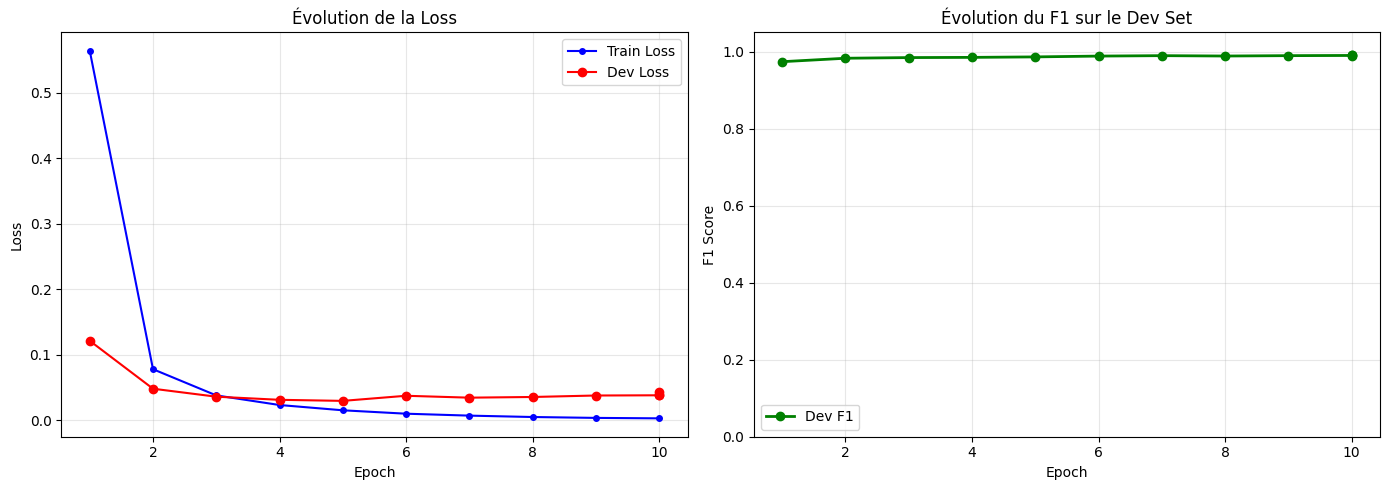

📈 Graphiques sauvegardés dans 'training_curves.png'


In [ ]:
# =====================================================================
# CELLULE 10 — Visualisation de la courbe d'entraînement
# =====================================================================
# On trace l'évolution de la loss et du F1 au fil des epochs pour
# vérifier que l'entraînement s'est bien passé.
#
# Ce qu'on veut voir :
# - La loss train qui descend → le modèle apprend
# - La loss dev qui descend aussi → pas d'overfitting
# - Si la loss dev remonte alors que la loss train descend → overfitting !

import matplotlib.pyplot as plt

# Extraire les logs d'entraînement
log_history = trainer.state.log_history

# Séparer les logs train et eval
train_losses = []
eval_losses = []
eval_f1s = []
epochs_train = []
epochs_eval = []

for log in log_history:
    if "loss" in log and "eval_loss" not in log:
        train_losses.append(log["loss"])
        epochs_train.append(log.get("epoch", 0))
    if "eval_loss" in log:
        eval_losses.append(log["eval_loss"])
        eval_f1s.append(log.get("eval_f1", 0))
        epochs_eval.append(log.get("epoch", 0))

# Graphique 1 : Loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_train, train_losses, 'b-o', label='Train Loss', markersize=4)
ax1.plot(epochs_eval, eval_losses, 'r-o', label='Dev Loss', markersize=6)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Évolution de la Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Graphique 2 : F1
ax2.plot(epochs_eval, eval_f1s, 'g-o', label='Dev F1', markersize=6, linewidth=2)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('F1 Score')
ax2.set_title('Évolution du F1 sur le Dev Set')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print("📈 Graphiques sauvegardés dans 'training_curves.png'")


In [ ]:
# =====================================================================
# CELLULE 11 — Sauvegarde du modèle final
# =====================================================================
# On sauvegarde le meilleur modèle dans un dossier propre.
# Ce dossier contient tout ce qu'il faut pour réutiliser le modèle :
# - Les poids du modèle (pytorch_model.bin ou model.safetensors)
# - La configuration (config.json)
# - Le tokenizer (sentencepiece.bpe.model, tokenizer.json, etc.)
#
# Tu pourras le recharger plus tard avec :
#   model = CamembertForTokenClassification.from_pretrained("./best_model")
#   tokenizer = CamembertTokenizerFast.from_pretrained("./best_model")

save_path = "./best_model"
trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)

print(f"\n💾 Modèle sauvegardé dans '{save_path}/'")
print(f"   Contenu :")
import os
for f in sorted(os.listdir(save_path)):
    size = os.path.getsize(os.path.join(save_path, f))
    if size > 1e6:
        print(f"   📄 {f} ({size/1e6:.1f} MB)")
    else:
        print(f"   📄 {f} ({size/1e3:.0f} KB)")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


💾 Modèle sauvegardé dans './best_model/'
   Contenu :
   📄 config.json (1 KB)
   📄 model.safetensors (440.2 MB)
   📄 tokenizer.json (2.1 MB)
   📄 tokenizer_config.json (0 KB)
   📄 training_args.bin (5 KB)


In [ ]:
# =====================================================================
# CELLULE 12 — Test rapide du modèle (vérification sanity check)
# =====================================================================
# Avant de passer à la Partie 4, on fait un test rapide avec quelques
# phrases pour vérifier visuellement que le modèle fonctionne.

from transformers import pipeline

# Créer un pipeline NER avec notre modèle fine-tuné
ner_pipeline = pipeline(
    "token-classification",
    model=save_path,
    tokenizer=save_path,
    aggregation_strategy="simple",  # Regroupe les sub-tokens en entités complètes
    device=0 if torch.cuda.is_available() else -1,
)

# Phrases de test couvrant différents cas
test_phrases = [
    "Je voudrais aller de Paris à Lyon",
    "un billet Marseille Bordeaux svp",
    "Comment me rendre à Toulouse depuis Nantes ?",
    "je veux aller a saint etienne en partant de lille",
    "Avec mon ami Albert, je voudrais aller de Tours à Paris",
    "Bonjour, quel temps fait-il aujourd'hui ?",  # INVALIDE
]

print("\n🧪 Test rapide du modèle :")
print("=" * 70)

for phrase in test_phrases:
    entities = ner_pipeline(phrase)

    # Extraire origines et destinations
    origins = [e['word'] for e in entities if 'ORIGIN' in e['entity_group']]
    dests = [e['word'] for e in entities if 'DEST' in e['entity_group']]

    print(f"\n📝 \"{phrase}\"")
    if origins or dests:
        print(f"   🟢 ORIGIN : {', '.join(origins) if origins else '—'}")
        print(f"   🔵 DEST   : {', '.join(dests) if dests else '—'}")
    else:
        print(f"   🔴 INVALID (aucune entité détectée)")

    # Détail des entités brutes (pour debug)
    if entities:
        for e in entities:
            print(f"      [{e['entity_group']}] '{e['word']}' (score: {e['score']:.4f})")

print("\n" + "=" * 70)
print("✅ Si les résultats sont cohérents, le modèle est prêt !")
print("   On passera à la Partie 4 pour une évaluation rigoureuse.")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


🧪 Test rapide du modèle :

📝 "Je voudrais aller de Paris à Lyon"
   🟢 ORIGIN : Paris
   🔵 DEST   : Lyon
      [ORIGIN] 'Paris' (score: 0.9989)
      [DEST] 'Lyon' (score: 0.9989)

📝 "un billet Marseille Bordeaux svp"
   🟢 ORIGIN : Marseille
   🔵 DEST   : Bordeaux
      [ORIGIN] 'Marseille' (score: 0.9989)
      [DEST] 'Bordeaux' (score: 0.9989)

📝 "Comment me rendre à Toulouse depuis Nantes ?"
   🟢 ORIGIN : Nantes
   🔵 DEST   : Toulouse
      [DEST] 'Toulouse' (score: 0.9989)
      [ORIGIN] 'Nantes' (score: 0.9989)

📝 "je veux aller a saint etienne en partant de lille"
   🟢 ORIGIN : lille
   🔵 DEST   : saint etienne
      [DEST] 'saint etienne' (score: 0.9991)
      [ORIGIN] 'lille' (score: 0.9991)

📝 "Avec mon ami Albert, je voudrais aller de Tours à Paris"
   🟢 ORIGIN : Tours
   🔵 DEST   : Paris
      [ORIGIN] 'Tours' (score: 0.9990)
      [DEST] 'Paris' (score: 0.9989)

📝 "Bonjour, quel temps fait-il aujourd'hui ?"
   🔴 INVALID (aucune entité détectée)

✅ Si les résultats sont cohé

In [ ]:
########################################################################
# PARTIE 4 — Évaluation et métriques détaillées
# Travel Order Resolver — Analyse complète des performances du modèle
########################################################################
# Cette partie se place APRÈS la Partie 3 dans ton notebook Colab.
# À ce stade, tu as :
#   - Un modèle entraîné (trainer ou modèle rechargé depuis ./best_model)
#   - Le dataset tokenisé avec les splits train/validation/test
#   - Les labels : ['O', 'B-ORIGIN', 'I-ORIGIN', 'B-DEST', 'I-DEST']
########################################################################

# =====================================================================
# CELLULE 1 — Imports et configuration
# =====================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
import torch
from transformers import pipeline
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Configuration des labels
label_list = ['O', 'B-ORIGIN', 'I-ORIGIN', 'B-DEST', 'I-DEST']
id2label = {i: label for i, label in enumerate(label_list)}
label2id = {label: i for i, label in enumerate(label_list)}

print("✅ Imports chargés")
print(f"   Labels : {label_list}")


✅ Imports chargés
   Labels : ['O', 'B-ORIGIN', 'I-ORIGIN', 'B-DEST', 'I-DEST']


In [ ]:
# =====================================================================
# CELLULE 2 — Prédictions sur le Test Set
# =====================================================================
# On génère les prédictions du modèle sur TOUT le test set.
# C'est la base pour toutes nos analyses.
#
# RAPPEL : Le test set n'a JAMAIS été vu pendant l'entraînement.
# C'est notre mesure honnête de la performance réelle.

print("🔄 Génération des prédictions sur le test set...")

# Prédictions brutes via le trainer
predictions_output = trainer.predict(dataset["test"])
logits = predictions_output.predictions
true_label_ids = predictions_output.label_ids

# Convertir les logits en prédictions (argmax)
pred_label_ids = np.argmax(logits, axis=-1)

print(f"✅ Prédictions générées")
print(f"   Nombre d'exemples : {len(true_label_ids)}")
print(f"   Shape des prédictions : {pred_label_ids.shape}")


🔄 Génération des prédictions sur le test set...


✅ Prédictions générées
   Nombre d'exemples : 2001
   Shape des prédictions : (2001, 46)


In [ ]:
# =====================================================================
# CELLULE 3 — Conversion en labels textuels (pour seqeval)
# =====================================================================
# seqeval attend des listes de labels textuels, pas des IDs numériques.
# On ignore les tokens à -100 (tokens spéciaux et sub-tokens non-premiers).

def convert_ids_to_labels(pred_ids, true_ids, id2label):
    """
    Convertit les IDs en labels textuels, en ignorant les -100.
    Retourne deux listes de listes : prédictions et références.
    """
    all_preds = []
    all_trues = []

    for preds, trues in zip(pred_ids, true_ids):
        pred_seq = []
        true_seq = []

        for p, t in zip(preds, trues):
            if t != -100:  # Ignorer les tokens spéciaux
                pred_seq.append(id2label[p])
                true_seq.append(id2label[t])

        all_preds.append(pred_seq)
        all_trues.append(true_seq)

    return all_preds, all_trues

pred_labels, true_labels = convert_ids_to_labels(pred_label_ids, true_label_ids, id2label)

print(f"✅ Conversion terminée")
print(f"   Exemple de prédiction : {pred_labels[0][:10]}...")
print(f"   Exemple de référence  : {true_labels[0][:10]}...")


✅ Conversion terminée
   Exemple de prédiction : ['O', 'O', 'O', 'O']...
   Exemple de référence  : ['O', 'O', 'O', 'O']...


In [ ]:
# =====================================================================
# CELLULE 4 — Métriques globales (seqeval)
# =====================================================================
# seqeval calcule les métriques au niveau des ENTITÉS, pas des tokens.
# Une entité est correcte seulement si :
#   1. Le type est bon (ORIGIN vs DEST)
#   2. Les frontières sont exactes (tous les tokens de l'entité)

print("\n" + "=" * 60)
print("📊 MÉTRIQUES GLOBALES (niveau entité)")
print("=" * 60)

precision = precision_score(true_labels, pred_labels)
recall = recall_score(true_labels, pred_labels)
f1 = f1_score(true_labels, pred_labels)

print(f"\n   Precision : {precision:.4f}")
print(f"   Recall    : {recall:.4f}")
print(f"   F1 Score  : {f1:.4f}")

# Interprétation
print("\n📖 Interprétation :")
print(f"   • Precision {precision:.1%} = quand le modèle trouve une entité,")
print(f"     il a raison {precision:.1%} du temps")
print(f"   • Recall {recall:.1%} = parmi toutes les vraies entités,")
print(f"     le modèle en trouve {recall:.1%}")
print(f"   • F1 {f1:.1%} = équilibre entre les deux")



📊 MÉTRIQUES GLOBALES (niveau entité)

   Precision : 0.9859
   Recall    : 0.9891
   F1 Score  : 0.9875

📖 Interprétation :
   • Precision 98.6% = quand le modèle trouve une entité,
     il a raison 98.6% du temps
   • Recall 98.9% = parmi toutes les vraies entités,
     le modèle en trouve 98.9%
   • F1 98.7% = équilibre entre les deux


In [ ]:
# =====================================================================
# CELLULE 5 — Rapport détaillé par type d'entité
# =====================================================================
# On veut voir si le modèle est meilleur sur ORIGIN ou DEST,
# et si les entités multi-tokens (I-XXX) posent problème.

print("\n" + "=" * 60)
print("📋 RAPPORT DÉTAILLÉ PAR TYPE D'ENTITÉ")
print("=" * 60)

report = classification_report(true_labels, pred_labels, digits=4)
print(report)

# Sauvegarder le rapport pour le document
with open('classification_report.txt', 'w') as f:
    f.write("RAPPORT DE CLASSIFICATION NER - CamemBERT Travel Resolver\n")
    f.write("=" * 60 + "\n\n")
    f.write(report)
print("💾 Rapport sauvegardé dans 'classification_report.txt'")



📋 RAPPORT DÉTAILLÉ PAR TYPE D'ENTITÉ
              precision    recall  f1-score   support

        DEST     0.9814    0.9890    0.9852      1547
      ORIGIN     0.9904    0.9891    0.9898      1566

   micro avg     0.9859    0.9891    0.9875      3113
   macro avg     0.9859    0.9891    0.9875      3113
weighted avg     0.9859    0.9891    0.9875      3113

💾 Rapport sauvegardé dans 'classification_report.txt'



🔢 MATRICE DE CONFUSION (niveau token)

Matrice (lignes = vrai, colonnes = prédit) :
              O  B-ORIGIN  I-ORIGIN  B-DEST  I-DEST
O         15881         9        21      19      49
B-ORIGIN      6      1554         1       5       0
I-ORIGIN      9         0      3709       2      16
B-DEST       13         1         0    1531       2
I-DEST       28         0         0       0    3759


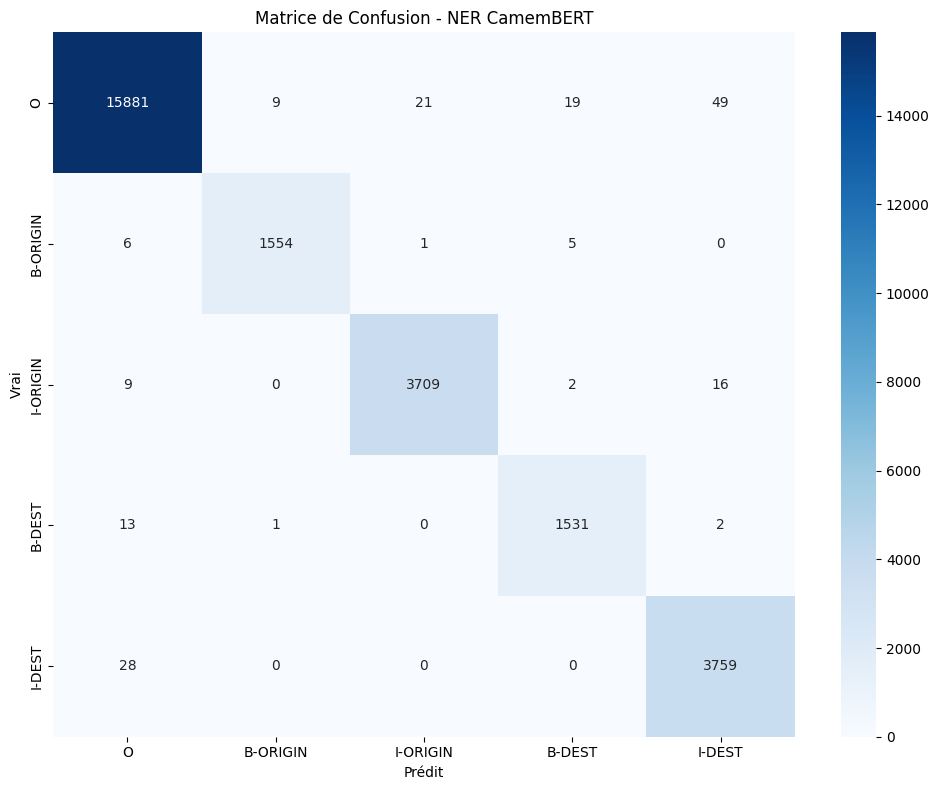

💾 Matrice sauvegardée dans 'confusion_matrix.png'

📖 Analyse des confusions :
   Total d'erreurs au niveau token : 181

   Top 5 des confusions :
   • O → I-DEST : 49 fois
   • I-DEST → O : 28 fois
   • O → I-ORIGIN : 21 fois
   • O → B-DEST : 19 fois
   • I-ORIGIN → I-DEST : 16 fois


In [ ]:
# =====================================================================
# CELLULE 6 — Matrice de confusion par token
# =====================================================================
# La matrice de confusion montre quels labels sont confondus.
# Attention : ici c'est au niveau TOKEN, pas entité.
# C'est utile pour voir si le modèle confond B-ORIGIN et B-DEST.

print("\n" + "=" * 60)
print("🔢 MATRICE DE CONFUSION (niveau token)")
print("=" * 60)

# Aplatir toutes les prédictions et références
flat_preds = [label for seq in pred_labels for label in seq]
flat_trues = [label for seq in true_labels for label in seq]

# Créer la matrice
cm = confusion_matrix(flat_trues, flat_preds, labels=label_list)

# Afficher en DataFrame pour lisibilité
cm_df = pd.DataFrame(cm, index=label_list, columns=label_list)
print("\nMatrice (lignes = vrai, colonnes = prédit) :")
print(cm_df)

# Visualisation
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_list, yticklabels=label_list)
plt.xlabel('Prédit')
plt.ylabel('Vrai')
plt.title('Matrice de Confusion - NER CamemBERT')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Matrice sauvegardée dans 'confusion_matrix.png'")

# Analyse des confusions principales
print("\n📖 Analyse des confusions :")
total_errors = cm.sum() - np.trace(cm)
print(f"   Total d'erreurs au niveau token : {total_errors}")

# Trouver les confusions les plus fréquentes (hors diagonale)
confusions = []
for i, true_label in enumerate(label_list):
    for j, pred_label in enumerate(label_list):
        if i != j and cm[i, j] > 0:
            confusions.append((true_label, pred_label, cm[i, j]))

confusions.sort(key=lambda x: x[2], reverse=True)
print("\n   Top 5 des confusions :")
for true_l, pred_l, count in confusions[:5]:
    print(f"   • {true_l} → {pred_l} : {count} fois")



📊 MATRICE DE CONFUSION NORMALISÉE (%)


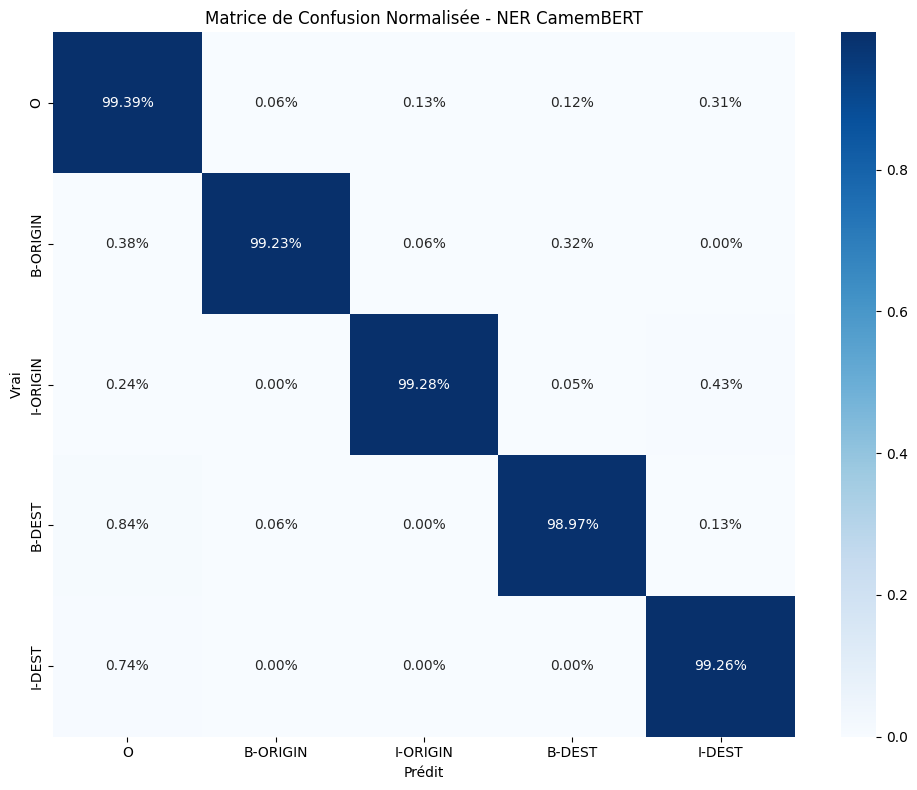


   Accuracy par label :
   • O          : 99.39%
   • B-ORIGIN   : 99.23%
   • I-ORIGIN   : 99.28%
   • B-DEST     : 98.97%
   • I-DEST     : 99.26%


In [ ]:
# =====================================================================
# CELLULE 7 — Matrice de confusion normalisée (pourcentages)
# =====================================================================
# Version normalisée pour voir les taux d'erreur relatifs.
# Utile quand les classes sont déséquilibrées (beaucoup de 'O').

print("\n" + "=" * 60)
print("📊 MATRICE DE CONFUSION NORMALISÉE (%)")
print("=" * 60)

# Normaliser par ligne (vrai label)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_normalized = np.nan_to_num(cm_normalized)  # Gérer division par 0

# Visualisation
plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=label_list, yticklabels=label_list)
plt.xlabel('Prédit')
plt.ylabel('Vrai')
plt.title('Matrice de Confusion Normalisée - NER CamemBERT')
plt.tight_layout()
plt.savefig('confusion_matrix_normalized.png', dpi=150, bbox_inches='tight')
plt.show()

# Accuracy par classe
print("\n   Accuracy par label :")
for i, label in enumerate(label_list):
    acc = cm_normalized[i, i]
    print(f"   • {label:10} : {acc:.2%}")


In [ ]:
# =====================================================================
# CELLULE 8 — Analyse des erreurs : exemples concrets
# =====================================================================
# C'est LA partie la plus utile. On va regarder des vraies phrases
# où le modèle s'est trompé pour comprendre pourquoi.

print("\n" + "=" * 60)
print("🔍 ANALYSE DES ERREURS : EXEMPLES CONCRETS")
print("=" * 60)

# On a besoin des phrases originales, pas juste des tokens
# On va utiliser le pipeline pour prédire sur les phrases brutes

# Charger le pipeline NER
ner_pipeline = pipeline(
    "token-classification",
    model="./best_model",
    tokenizer="./best_model",
    aggregation_strategy="simple",
    device=0 if torch.cuda.is_available() else -1,
)

# Recharger les données originales pour avoir les phrases
# (on suppose que tu as encore 'examples' de la Partie 2, sinon on recharge)
try:
    _ = examples[0]
    print("✅ Données originales disponibles")
except NameError:
    import json
    with open('camembert_data/bio_dataset.json', 'r', encoding='utf-8') as f:
        examples = [json.loads(line) for line in f if line.strip()]
    print("✅ Données rechargées depuis bio_dataset.json")

# Séparer en train/val/test avec les mêmes proportions
from sklearn.model_selection import train_test_split
train_examples, temp_examples = train_test_split(examples, test_size=0.2, random_state=42)
val_examples, test_examples = train_test_split(temp_examples, test_size=0.5, random_state=42)

print(f"   Exemples de test : {len(test_examples)}")



🔍 ANALYSE DES ERREURS : EXEMPLES CONCRETS


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ Données originales disponibles
   Exemples de test : 2000


In [ ]:
# =====================================================================
# CELLULE 9 — Identifier et catégoriser les erreurs
# =====================================================================

def extract_entities_from_example(example):
    """Extrait les entités attendues depuis un exemple du dataset."""
    tokens = example['tokens']
    labels = example['labels']

    entities = {'ORIGIN': [], 'DEST': []}
    current_entity = []
    current_type = None

    for token, label in zip(tokens, labels):
        if label.startswith('B-'):
            # Sauvegarder l'entité précédente si existe
            if current_entity and current_type:
                entities[current_type].append(' '.join(current_entity))
            # Commencer nouvelle entité
            current_type = label[2:]  # 'ORIGIN' ou 'DEST'
            current_entity = [token]
        elif label.startswith('I-') and current_type:
            current_entity.append(token)
        else:
            # Fin d'entité
            if current_entity and current_type:
                entities[current_type].append(' '.join(current_entity))
            current_entity = []
            current_type = None

    # Dernière entité
    if current_entity and current_type:
        entities[current_type].append(' '.join(current_entity))

    return entities

def extract_entities_from_prediction(ner_result):
    """Extrait les entités depuis la sortie du pipeline NER."""
    entities = {'ORIGIN': [], 'DEST': []}

    for ent in ner_result:
        entity_type = ent['entity_group'].replace('B-', '').replace('I-', '')
        if entity_type in entities:
            entities[entity_type].append(ent['word'].strip())

    return entities

def compare_entities(expected, predicted):
    """Compare les entités attendues et prédites, retourne le type d'erreur."""
    errors = []

    for entity_type in ['ORIGIN', 'DEST']:
        exp_set = set(e.lower() for e in expected[entity_type])
        pred_set = set(e.lower() for e in predicted[entity_type])

        # Entités manquées (dans expected mais pas dans predicted)
        missed = exp_set - pred_set
        for m in missed:
            errors.append(('MISSED', entity_type, m))

        # Fausses détections (dans predicted mais pas dans expected)
        false_pos = pred_set - exp_set
        for fp in false_pos:
            errors.append(('FALSE_POS', entity_type, fp))

    # Vérifier les inversions ORIGIN↔DEST
    exp_origins = set(e.lower() for e in expected['ORIGIN'])
    exp_dests = set(e.lower() for e in expected['DEST'])
    pred_origins = set(e.lower() for e in predicted['ORIGIN'])
    pred_dests = set(e.lower() for e in predicted['DEST'])

    # Une ville attendue en ORIGIN mais prédite en DEST
    inverted_to_dest = exp_origins & pred_dests
    for inv in inverted_to_dest:
        errors.append(('INVERTED', 'ORIGIN→DEST', inv))

    # Une ville attendue en DEST mais prédite en ORIGIN
    inverted_to_origin = exp_dests & pred_origins
    for inv in inverted_to_origin:
        errors.append(('INVERTED', 'DEST→ORIGIN', inv))

    return errors

# Analyser toutes les erreurs sur le test set
print("🔄 Analyse des erreurs sur le test set...")

all_errors = []
error_examples = []

for i, example in enumerate(test_examples):
    sentence = ' '.join(example['tokens'])
    expected = extract_entities_from_example(example)

    # Prédiction du modèle
    try:
        ner_result = ner_pipeline(sentence)
        predicted = extract_entities_from_prediction(ner_result)
    except Exception as e:
        predicted = {'ORIGIN': [], 'DEST': []}

    # Comparer
    errors = compare_entities(expected, predicted)

    if errors:
        error_examples.append({
            'sentence': sentence,
            'expected': expected,
            'predicted': predicted,
            'errors': errors,
            'is_valid': example.get('is_valid', True)
        })
        all_errors.extend(errors)

print(f"\n✅ Analyse terminée")
print(f"   Phrases avec erreurs : {len(error_examples)} / {len(test_examples)}")
print(f"   Taux d'erreur : {len(error_examples)/len(test_examples):.1%}")


🔄 Analyse des erreurs sur le test set...


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



✅ Analyse terminée
   Phrases avec erreurs : 15 / 2000
   Taux d'erreur : 0.8%


In [ ]:
# =====================================================================
# CELLULE 10 — Statistiques des types d'erreurs
# =====================================================================

print("\n" + "=" * 60)
print("📊 STATISTIQUES DES TYPES D'ERREURS")
print("=" * 60)

error_counts = Counter(e[0] for e in all_errors)
error_details = Counter((e[0], e[1]) for e in all_errors)

print("\n   Par type d'erreur :")
for error_type, count in error_counts.most_common():
    desc = {
        'MISSED': 'Entités non détectées',
        'FALSE_POS': 'Fausses détections',
        'INVERTED': 'Inversions ORIGIN↔DEST'
    }
    print(f"   • {desc.get(error_type, error_type):30} : {count}")

print("\n   Détail par type + entité :")
for (error_type, entity_type), count in error_details.most_common(10):
    print(f"   • {error_type:12} {entity_type:15} : {count}")



📊 STATISTIQUES DES TYPES D'ERREURS

   Par type d'erreur :
   • Fausses détections             : 11
   • Entités non détectées          : 8
   • Inversions ORIGIN↔DEST         : 2

   Détail par type + entité :
   • FALSE_POS    DEST            : 9
   • MISSED       DEST            : 5
   • MISSED       ORIGIN          : 3
   • FALSE_POS    ORIGIN          : 2
   • INVERTED     ORIGIN→DEST     : 1
   • INVERTED     DEST→ORIGIN     : 1


In [ ]:
# =====================================================================
# CELLULE 11 — Exemples d'erreurs par catégorie
# =====================================================================

print("\n" + "=" * 60)
print("🔍 EXEMPLES D'ERREURS PAR CATÉGORIE")
print("=" * 60)

def show_error_examples(error_type, n=3):
    """Affiche n exemples d'un type d'erreur."""
    examples_of_type = [ex for ex in error_examples
                        if any(e[0] == error_type for e in ex['errors'])]

    print(f"\n--- {error_type} ({len(examples_of_type)} cas) ---")

    for ex in examples_of_type[:n]:
        print(f"\n   📝 \"{ex['sentence']}\"")
        print(f"      Attendu  : ORIGIN={ex['expected']['ORIGIN']}, DEST={ex['expected']['DEST']}")
        print(f"      Prédit   : ORIGIN={ex['predicted']['ORIGIN']}, DEST={ex['predicted']['DEST']}")
        relevant_errors = [e for e in ex['errors'] if e[0] == error_type]
        for e in relevant_errors:
            print(f"      ❌ {e[0]} {e[1]}: '{e[2]}'")

show_error_examples('MISSED', 5)
show_error_examples('FALSE_POS', 5)
show_error_examples('INVERTED', 5)



🔍 EXEMPLES D'ERREURS PAR CATÉGORIE

--- MISSED (8 cas) ---

   📝 "De Paris-Gare-de-Lyon à Paris-Nord"
      Attendu  : ORIGIN=['Paris-Gare-de-Lyon'], DEST=[]
      Prédit   : ORIGIN=[], DEST=['Paris-Gare-de-Lyon']
      ❌ MISSED ORIGIN: 'paris-gare-de-lyon'

   📝 "dax les thermes un billet depuis bayonne"
      Attendu  : ORIGIN=['bayonne'], DEST=['dax']
      Prédit   : ORIGIN=['dax', 'bayonne'], DEST=['les thermes']
      ❌ MISSED DEST: 'dax'

   📝 "de viyeherviers en dirextion de voviez svp"
      Attendu  : ORIGIN=['viyeherviers'], DEST=['voviez']
      Prédit   : ORIGIN=['viyeherviers'], DEST=[]
      ❌ MISSED DEST: 'voviez'

   📝 "au départ de troyes en dirrction de shamberry"
      Attendu  : ORIGIN=['troyes'], DEST=['shamberry']
      Prédit   : ORIGIN=['troyes'], DEST=[]
      ❌ MISSED DEST: 'shamberry'

   📝 "billet pour rannes sepuis le havre"
      Attendu  : ORIGIN=['le havre'], DEST=['rannes']
      Prédit   : ORIGIN=[], DEST=['rannes']
      ❌ MISSED ORIGIN: 'le havre'


In [ ]:
# =====================================================================
# CELLULE 12 — Performance sur les phrases INVALIDES
# =====================================================================
# Les phrases invalides (pas de voyage) doivent retourner INVALID.
# Le modèle doit ne détecter AUCUNE entité pour ces phrases.

print("\n" + "=" * 60)
print("🚫 PERFORMANCE SUR LES PHRASES INVALIDES")
print("=" * 60)

invalid_examples = [ex for ex in test_examples if not ex.get('is_valid', True)]
valid_examples = [ex for ex in test_examples if ex.get('is_valid', True)]

print(f"\n   Phrases invalides dans le test set : {len(invalid_examples)}")
print(f"   Phrases valides dans le test set : {len(valid_examples)}")

# Analyser les invalides
correct_invalid = 0
false_positive_invalid = 0

for example in invalid_examples:
    sentence = ' '.join(example['tokens'])
    try:
        ner_result = ner_pipeline(sentence)
        has_entities = len(ner_result) > 0
    except:
        has_entities = False

    if not has_entities:
        correct_invalid += 1
    else:
        false_positive_invalid += 1

if len(invalid_examples) > 0:
    invalid_accuracy = correct_invalid / len(invalid_examples)
    print(f"\n   ✅ Correctement identifiées comme invalides : {correct_invalid} ({invalid_accuracy:.1%})")
    print(f"   ❌ Faux positifs (entités détectées à tort) : {false_positive_invalid} ({1-invalid_accuracy:.1%})")
else:
    print("   ⚠️ Pas de phrases invalides dans le test set")



🚫 PERFORMANCE SUR LES PHRASES INVALIDES

   Phrases invalides dans le test set : 422
   Phrases valides dans le test set : 1578

   ✅ Correctement identifiées comme invalides : 422 (100.0%)
   ❌ Faux positifs (entités détectées à tort) : 0 (0.0%)


In [ ]:
# =====================================================================
# CELLULE 13 — Performance par catégorie de difficulté
# =====================================================================
# Si ton dataset contient des catégories (normal, fautes, SMS, etc.),
# on peut mesurer la performance par catégorie.

print("\n" + "=" * 60)
print("📈 PERFORMANCE PAR CATÉGORIE DE DIFFICULTÉ")
print("=" * 60)

# Essayer de détecter les catégories automatiquement
def categorize_sentence(sentence):
    """Catégorise une phrase selon ses caractéristiques."""
    sentence_lower = sentence.lower()

    # SMS / abréviations
    sms_indicators = ['stp', 'svp', 'pk', 'pq', 'jsp', 'tkt', 'mrc', 'bjr']
    if any(ind in sentence_lower.split() for ind in sms_indicators):
        return 'SMS/Abréviations'

    # Sans majuscules (tout en minuscules)
    if sentence == sentence.lower() and any(c.isalpha() for c in sentence):
        return 'Sans majuscules'

    # Villes composées (avec tiret)
    if '-' in sentence and any(word.count('-') >= 1 and word[0].isupper()
                               for word in sentence.split() if '-' in word):
        return 'Villes composées'

    # Détection de fautes possibles (heuristique simple)
    # Si des mots courants sont mal orthographiés

    return 'Standard'

# Catégoriser et mesurer
category_results = defaultdict(lambda: {'correct': 0, 'total': 0})

for example in test_examples:
    sentence = ' '.join(example['tokens'])
    category = categorize_sentence(sentence)
    expected = extract_entities_from_example(example)

    try:
        ner_result = ner_pipeline(sentence)
        predicted = extract_entities_from_prediction(ner_result)
    except:
        predicted = {'ORIGIN': [], 'DEST': []}

    # Vérifier si la prédiction est exactement correcte
    exp_origins = set(e.lower() for e in expected['ORIGIN'])
    exp_dests = set(e.lower() for e in expected['DEST'])
    pred_origins = set(e.lower() for e in predicted['ORIGIN'])
    pred_dests = set(e.lower() for e in predicted['DEST'])

    is_correct = (exp_origins == pred_origins and exp_dests == pred_dests)

    category_results[category]['total'] += 1
    if is_correct:
        category_results[category]['correct'] += 1

print("\n   Accuracy par catégorie :")
print("   " + "-" * 45)
for category, results in sorted(category_results.items(),
                                 key=lambda x: x[1]['total'], reverse=True):
    acc = results['correct'] / results['total'] if results['total'] > 0 else 0
    print(f"   {category:25} : {acc:6.1%} ({results['correct']}/{results['total']})")



📈 PERFORMANCE PAR CATÉGORIE DE DIFFICULTÉ

   Accuracy par catégorie :
   ---------------------------------------------
   Standard                  : 100.0% (838/838)
   Villes composées          :  99.8% (645/646)
   Sans majuscules           :  97.3% (469/482)
   SMS/Abréviations          :  97.1% (33/34)



📊 GRAPHIQUES RÉCAPITULATIFS


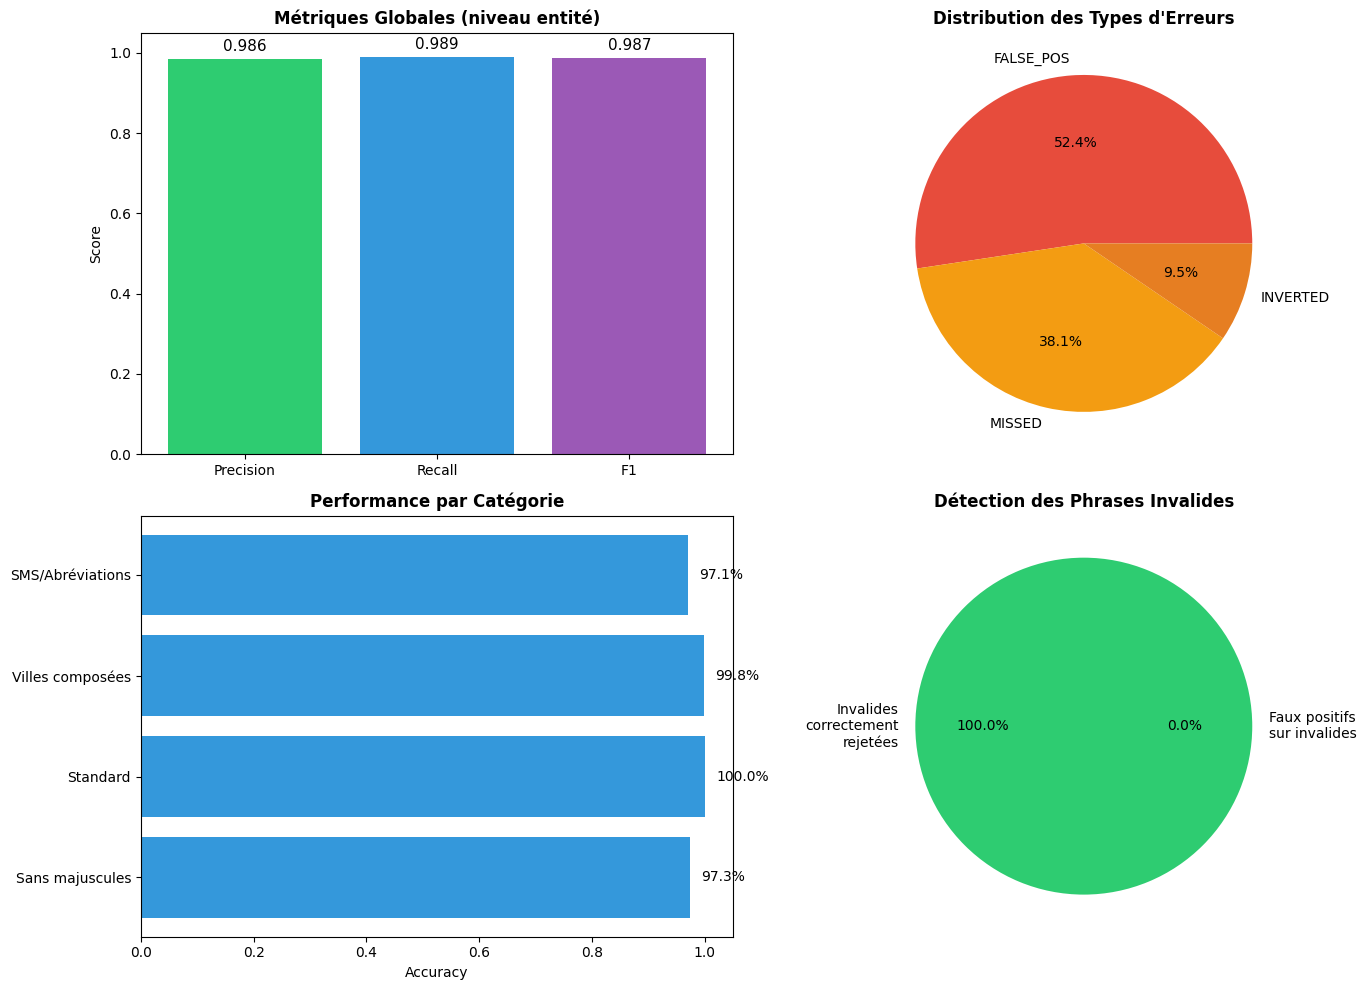

💾 Graphique sauvegardé dans 'evaluation_summary.png'


In [ ]:
# =====================================================================
# CELLULE 14 — Graphique récapitulatif des performances
# =====================================================================

print("\n" + "=" * 60)
print("📊 GRAPHIQUES RÉCAPITULATIFS")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Métriques globales
ax1 = axes[0, 0]
metrics = ['Precision', 'Recall', 'F1']
values = [precision, recall, f1]
colors = ['#2ecc71', '#3498db', '#9b59b6']
bars = ax1.bar(metrics, values, color=colors)
ax1.set_ylim(0, 1.05)
ax1.set_title('Métriques Globales (niveau entité)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Score')
for bar, val in zip(bars, values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{val:.3f}', ha='center', fontsize=11)

# 2. Distribution des erreurs
ax2 = axes[0, 1]
if error_counts:
    error_types = list(error_counts.keys())
    error_values = list(error_counts.values())
    colors2 = ['#e74c3c', '#f39c12', '#e67e22'][:len(error_types)]
    ax2.pie(error_values, labels=error_types, autopct='%1.1f%%', colors=colors2)
    ax2.set_title('Distribution des Types d\'Erreurs', fontsize=12, fontweight='bold')
else:
    ax2.text(0.5, 0.5, 'Aucune erreur !', ha='center', va='center', fontsize=14)
    ax2.set_title('Distribution des Types d\'Erreurs', fontsize=12, fontweight='bold')

# 3. Performance par catégorie
ax3 = axes[1, 0]
categories = list(category_results.keys())
accuracies = [category_results[c]['correct']/category_results[c]['total']
              if category_results[c]['total'] > 0 else 0 for c in categories]
y_pos = np.arange(len(categories))
bars3 = ax3.barh(y_pos, accuracies, color='#3498db')
ax3.set_yticks(y_pos)
ax3.set_yticklabels(categories)
ax3.set_xlim(0, 1.05)
ax3.set_xlabel('Accuracy')
ax3.set_title('Performance par Catégorie', fontsize=12, fontweight='bold')
for bar, val in zip(bars3, accuracies):
    ax3.text(val + 0.02, bar.get_y() + bar.get_height()/2,
             f'{val:.1%}', va='center', fontsize=10)

# 4. Valides vs Invalides
ax4 = axes[1, 1]
if len(invalid_examples) > 0:
    labels_pie = ['Invalides\ncorrectement\nrejetées', 'Faux positifs\nsur invalides']
    sizes = [correct_invalid, false_positive_invalid]
    colors4 = ['#2ecc71', '#e74c3c']
    ax4.pie(sizes, labels=labels_pie, autopct='%1.1f%%', colors=colors4)
    ax4.set_title('Détection des Phrases Invalides', fontsize=12, fontweight='bold')
else:
    valid_errors = len([ex for ex in error_examples if ex['is_valid']])
    valid_correct = len(valid_examples) - valid_errors
    labels_pie = ['Prédictions\ncorrectes', 'Erreurs']
    sizes = [valid_correct, valid_errors]
    colors4 = ['#2ecc71', '#e74c3c']
    ax4.pie(sizes, labels=labels_pie, autopct='%1.1f%%', colors=colors4)
    ax4.set_title('Résultats sur Phrases Valides', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('evaluation_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Graphique sauvegardé dans 'evaluation_summary.png'")


In [ ]:
# =====================================================================
# CELLULE 15 — Résumé pour le rapport
# =====================================================================

print("\n" + "=" * 60)
print("📝 RÉSUMÉ POUR LE RAPPORT EPITECH")
print("=" * 60)

summary = f"""
RÉSUMÉ DES PERFORMANCES - CamemBERT NER Travel Resolver
========================================================

1. MÉTRIQUES GLOBALES (niveau entité, test set)
   - Precision : {precision:.4f} ({precision:.1%})
   - Recall    : {recall:.4f} ({recall:.1%})
   - F1 Score  : {f1:.4f} ({f1:.1%})

2. ANALYSE DES ERREURS
   - Phrases avec au moins une erreur : {len(error_examples)} / {len(test_examples)} ({len(error_examples)/len(test_examples):.1%})
   - Types d'erreurs : {dict(error_counts)}

3. PERFORMANCE PAR CATÉGORIE
"""

for category, results in sorted(category_results.items(),
                                 key=lambda x: x[1]['total'], reverse=True):
    acc = results['correct'] / results['total'] if results['total'] > 0 else 0
    summary += f"   - {category}: {acc:.1%} ({results['correct']}/{results['total']})\n"

if len(invalid_examples) > 0:
    summary += f"""
4. DÉTECTION DES PHRASES INVALIDES
   - Correctement rejetées : {correct_invalid}/{len(invalid_examples)} ({correct_invalid/len(invalid_examples):.1%})
   - Faux positifs : {false_positive_invalid}/{len(invalid_examples)} ({false_positive_invalid/len(invalid_examples):.1%})
"""

summary += """
5. FICHIERS GÉNÉRÉS
   - classification_report.txt : rapport détaillé seqeval
   - confusion_matrix.png : matrice de confusion
   - confusion_matrix_normalized.png : matrice normalisée
   - evaluation_summary.png : graphiques récapitulatifs
"""

print(summary)

# Sauvegarder le résumé
with open('evaluation_summary.txt', 'w', encoding='utf-8') as f:
    f.write(summary)
print("💾 Résumé sauvegardé dans 'evaluation_summary.txt'")

print("\n" + "=" * 60)
print("✅ PARTIE 4 TERMINÉE !")
print("=" * 60)
print("""
Prochaine étape : Partie 5 — Pipeline d'inférence et post-traitement
   → Transformer la sortie du modèle en format exploitable
   → Fuzzy matching vers les vrais noms de gares
   → Format de sortie conforme aux specs du sujet
""")


In [ ]:
########################################################################
# TEST DU MODÈLE — Phrases de test couvrant tous les cas difficiles
# Travel Order Resolver — Vérification manuelle des performances
########################################################################
# Exécute ce script après avoir entraîné ton modèle (Partie 3).
# Il teste le modèle sur des phrases représentatives de chaque catégorie.
########################################################################

# =====================================================================
# CELLULE 1 — Charger le pipeline NER
# =====================================================================

from transformers import pipeline
import torch

# Charger le modèle entraîné
ner_pipeline = pipeline(
    "token-classification",
    model="./best_model",
    tokenizer="./best_model",
    aggregation_strategy="simple",
    device=0 if torch.cuda.is_available() else -1,
)

print("✅ Modèle chargé")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ Modèle chargé


In [ ]:
# =====================================================================
# CELLULE 2 — Liste de phrases de test par catégorie
# =====================================================================

test_cases = {
    # -----------------------------------------------------------------
    # CATÉGORIE 1 : Phrases standard (majuscules, syntaxe correcte)
    # -----------------------------------------------------------------
    "Standard": [
        ("Je voudrais aller de Paris à Lyon", "Paris", "Lyon"),
        ("Un billet de Marseille à Bordeaux s'il vous plaît", "Marseille", "Bordeaux"),
        ("Je souhaite me rendre à Toulouse depuis Nantes", "Nantes", "Toulouse"),
        ("Comment aller de Lille à Strasbourg ?", "Lille", "Strasbourg"),
        ("Je veux partir de Nice pour aller à Montpellier", "Nice", "Montpellier"),
    ],

    # -----------------------------------------------------------------
    # CATÉGORIE 2 : Sans majuscules (tout en minuscules)
    # -----------------------------------------------------------------
    "Sans majuscules": [
        ("je veux aller de paris à lyon", "paris", "lyon"),
        ("un billet marseille bordeaux", "marseille", "bordeaux"),
        ("de lille à strasbourg demain matin", "lille", "strasbourg"),
        ("comment me rendre à toulouse depuis nantes", "nantes", "toulouse"),
        ("je pars de nice direction montpellier", "nice", "montpellier"),
    ],

    # -----------------------------------------------------------------
    # CATÉGORIE 3 : Fautes d'orthographe
    # -----------------------------------------------------------------
    "Fautes d'orthographe": [
        ("Je veux aller de Pari à Liyon", "Pari", "Liyon"),
        ("Un billet Marsaille Bordeau", "Marsaille", "Bordeau"),
        ("De Toulous à Nante svp", "Toulous", "Nante"),
        ("je voudrais aller a strasbour depuis lile", "lile", "strasbour"),
        ("Monpelier à Niice", "Monpelier", "Niice"),
    ],

    # -----------------------------------------------------------------
    # CATÉGORIE 4 : Style SMS / abréviations
    # -----------------------------------------------------------------
    "SMS et abréviations": [
        ("bjr je veux aller de paris a lyon stp", "paris", "lyon"),
        ("1 billet marseille bordeaux svp mrc", "marseille", "bordeaux"),
        ("pk y a pas de train lille strasbourg ?", "lille", "strasbourg"),
        ("slt jsuis a nantes jveux aller toulouse", "nantes", "toulouse"),
        ("cc train nice montpellier dispo ?", "nice", "montpellier"),
    ],

    # -----------------------------------------------------------------
    # CATÉGORIE 5 : Villes composées (avec tiret)
    # -----------------------------------------------------------------
    "Villes composées": [
        ("Je veux aller de Saint-Étienne à Clermont-Ferrand", "Saint-Étienne", "Clermont-Ferrand"),
        ("Un billet Aix-en-Provence à Saint-Malo", "Aix-en-Provence", "Saint-Malo"),
        ("De Vitry-sur-Seine à Neuilly-sur-Seine", "Vitry-sur-Seine", "Neuilly-sur-Seine"),
        ("Comment aller à La Roche-sur-Yon depuis Les Sables-d'Olonne", "Les Sables-d'Olonne", "La Roche-sur-Yon"),
        ("de saint-etienne a clermont-ferrand", "saint-etienne", "clermont-ferrand"),
    ],

    # -----------------------------------------------------------------
    # CATÉGORIE 6 : Pièges prénoms-villes (Albert, Florence, etc.)
    # -----------------------------------------------------------------
    "Pièges prénoms-villes": [
        ("Je veux aller à Tours voir mon ami Albert en partant de Bordeaux", "Bordeaux", "Tours"),
        ("Avec mes amis Florence et Paris, je voudrais aller de Paris à Florence", "Paris", "Florence"),
        ("Mon cousin Victor habite à Nancy, je pars de Metz", "Metz", "Nancy"),
        ("Je rejoins mon ami Valence à Lyon depuis Grenoble", "Grenoble", "Lyon"),
        ("Charlotte m'attend à Rennes, je pars de Laval", "Laval", "Rennes"),
    ],

    # -----------------------------------------------------------------
    # CATÉGORIE 7 : Ordre inversé (destination avant origine)
    # -----------------------------------------------------------------
    "Ordre inversé": [
        ("À Lyon depuis Paris", "Paris", "Lyon"),
        ("Direction Bordeaux en partant de Toulouse", "Toulouse", "Bordeaux"),
        ("Vers Strasbourg, départ de Metz", "Metz", "Strasbourg"),
        ("Pour Nice au départ de Marseille", "Marseille", "Nice"),
        ("Destination Nantes, origine Rennes", "Rennes", "Nantes"),
    ],

    # -----------------------------------------------------------------
    # CATÉGORIE 8 : Formulations variées
    # -----------------------------------------------------------------
    "Formulations variées": [
        ("Je voudrais un billet Toulouse Paris", "Toulouse", "Paris"),
        ("À quelle heure y a-t-il des trains vers Paris en partance de Toulouse ?", "Toulouse", "Paris"),
        ("Trains disponibles Lyon Marseille ?", "Lyon", "Marseille"),
        ("Horaires Nantes Bordeaux demain", "Nantes", "Bordeaux"),
        ("Y a-t-il un TGV de Lille à Bruxelles ?", "Lille", "Bruxelles"),
    ],

    # -----------------------------------------------------------------
    # CATÉGORIE 9 : Phrases INVALIDES (pas de voyage)
    # -----------------------------------------------------------------
    "Invalides": [
        ("Bonjour, quel temps fait-il aujourd'hui ?", "INVALID", ""),
        ("Je cherche un bon restaurant à Paris", "INVALID", ""),
        ("Quelle est la capitale de la France ?", "INVALID", ""),
        ("Mon train a du retard", "INVALID", ""),
        ("Merci pour votre aide", "INVALID", ""),
        ("À quelle heure ferme la gare ?", "INVALID", ""),
        ("Je voudrais annuler ma réservation", "INVALID", ""),
        ("Le wifi fonctionne dans le train ?", "INVALID", ""),
    ],

    # -----------------------------------------------------------------
    # CATÉGORIE 10 : Cas très difficiles (combinaisons)
    # -----------------------------------------------------------------
    "Cas très difficiles": [
        ("jsuis a saint etienne jveux aller a clermont ferrand stp", "saint etienne", "clermont ferrand"),
        ("avec mon pote albert on va de tours a paris", "tours", "paris"),
        ("bjr billet aix en provence saint malo mrc", "aix en provence", "saint malo"),
        ("mon ami victor et moi on part de nancy vers metz", "nancy", "metz"),
        ("cc ya des trains de lile a strasbour ?", "lile", "strasbour"),
    ],
}


In [ ]:
# =====================================================================
# CELLULE 3 — Fonction de test et affichage
# =====================================================================

def test_model(ner_pipeline, test_cases):
    """
    Teste le modèle sur toutes les phrases et affiche les résultats.
    """
    results = {}
    total_correct = 0
    total_tests = 0

    print("=" * 80)
    print("🧪 TEST DU MODÈLE NER - CamemBERT Travel Resolver")
    print("=" * 80)

    for category, phrases in test_cases.items():
        print(f"\n{'─' * 80}")
        print(f"📁 CATÉGORIE : {category}")
        print(f"{'─' * 80}")

        category_correct = 0

        for sentence, expected_origin, expected_dest in phrases:
            total_tests += 1

            # Prédiction du modèle
            try:
                entities = ner_pipeline(sentence)
            except Exception as e:
                entities = []

            # Extraire origine et destination prédites
            pred_origins = [e['word'].strip() for e in entities if 'ORIGIN' in e['entity_group']]
            pred_dests = [e['word'].strip() for e in entities if 'DEST' in e['entity_group']]

            pred_origin = pred_origins[0] if pred_origins else ""
            pred_dest = pred_dests[0] if pred_dests else ""

            # Pour les invalides : correct si aucune entité détectée
            if expected_origin == "INVALID":
                is_correct = (len(entities) == 0)
            else:
                # Comparaison insensible à la casse et aux espaces
                origin_match = pred_origin.lower().strip() == expected_origin.lower().strip()
                dest_match = pred_dest.lower().strip() == expected_dest.lower().strip()
                is_correct = origin_match and dest_match

            if is_correct:
                category_correct += 1
                total_correct += 1
                status = "✅"
            else:
                status = "❌"

            # Affichage
            print(f"\n{status} \"{sentence}\"")
            if expected_origin == "INVALID":
                print(f"   Attendu  : INVALID")
                print(f"   Prédit   : {'INVALID' if len(entities) == 0 else f'ORIGIN={pred_origin}, DEST={pred_dest}'}")
            else:
                print(f"   Attendu  : ORIGIN=\"{expected_origin}\" → DEST=\"{expected_dest}\"")
                print(f"   Prédit   : ORIGIN=\"{pred_origin}\" → DEST=\"{pred_dest}\"")

            # Détail des entités brutes si erreur
            if not is_correct and entities:
                print(f"   Entités brutes : {[(e['word'], e['entity_group'], round(e['score'], 2)) for e in entities]}")

        # Résumé de la catégorie
        category_acc = category_correct / len(phrases) * 100
        results[category] = {'correct': category_correct, 'total': len(phrases), 'accuracy': category_acc}
        print(f"\n   📊 Résultat {category}: {category_correct}/{len(phrases)} ({category_acc:.0f}%)")

    return results, total_correct, total_tests


In [ ]:
# =====================================================================
# CELLULE 4 — Lancer les tests et afficher le résumé
# =====================================================================

results, total_correct, total_tests = test_model(ner_pipeline, test_cases)

# Résumé global
print("\n" + "=" * 80)
print("📊 RÉSUMÉ GLOBAL")
print("=" * 80)

print(f"\n   Score total : {total_correct}/{total_tests} ({total_correct/total_tests*100:.1f}%)")
print("\n   Détail par catégorie :")
print("   " + "-" * 50)

for category, data in sorted(results.items(), key=lambda x: x[1]['accuracy'], reverse=True):
    bar_len = int(data['accuracy'] / 5)  # Barre sur 20 caractères max
    bar = "█" * bar_len + "░" * (20 - bar_len)
    print(f"   {category:25} {bar} {data['accuracy']:5.1f}% ({data['correct']}/{data['total']})")

# Points forts et points faibles
print("\n   🎯 Points forts (>= 80%) :")
for cat, data in results.items():
    if data['accuracy'] >= 80:
        print(f"      • {cat}")

print("\n   ⚠️  Points à améliorer (< 80%) :")
for cat, data in results.items():
    if data['accuracy'] < 80:
        print(f"      • {cat} ({data['accuracy']:.0f}%)")

print("\n" + "=" * 80)
print("✅ Tests terminés !")
print("=" * 80)


🧪 TEST DU MODÈLE NER - CamemBERT Travel Resolver

────────────────────────────────────────────────────────────────────────────────
📁 CATÉGORIE : Standard
────────────────────────────────────────────────────────────────────────────────

✅ "Je voudrais aller de Paris à Lyon"
   Attendu  : ORIGIN="Paris" → DEST="Lyon"
   Prédit   : ORIGIN="Paris" → DEST="Lyon"

✅ "Un billet de Marseille à Bordeaux s'il vous plaît"
   Attendu  : ORIGIN="Marseille" → DEST="Bordeaux"
   Prédit   : ORIGIN="Marseille" → DEST="Bordeaux"

✅ "Je souhaite me rendre à Toulouse depuis Nantes"
   Attendu  : ORIGIN="Nantes" → DEST="Toulouse"
   Prédit   : ORIGIN="Nantes" → DEST="Toulouse"

✅ "Comment aller de Lille à Strasbourg ?"
   Attendu  : ORIGIN="Lille" → DEST="Strasbourg"
   Prédit   : ORIGIN="Lille" → DEST="Strasbourg"

✅ "Je veux partir de Nice pour aller à Montpellier"
   Attendu  : ORIGIN="Nice" → DEST="Montpellier"
   Prédit   : ORIGIN="Nice" → DEST="Montpellier"

   📊 Résultat Standard: 5/5 (100%)

──────

In [ ]:
# Zipper le dossier du modèle puis télécharger
import shutil
from google.colab import files

# Créer une archive ZIP du modèle
shutil.make_archive('best_model', 'zip', './best_model')

# Télécharger le ZIP
files.download('best_model.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Monter Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Copier le modèle vers Drive
import shutil

# Créer le dossier de destination
!mkdir -p "/content/drive/MyDrive/CamemBERT_NER_Travel"

# Copier le modèle
shutil.copytree('./best_model', '/content/drive/MyDrive/CamemBERT_NER_Travel/best_model', dirs_exist_ok=True)

# Ou si tu veux aussi copier camembert-v2
# shutil.copytree('./camembert-v2', '/content/drive/MyDrive/CamemBERT_NER_Travel/camembert-v2', dirs_exist_ok=True)

print("✅ Modèle sauvegardé sur Google Drive !")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Modèle sauvegardé sur Google Drive !
